# Notebook 1 — Dự báo cầu cho Dynamic Pricing Engine hàng tươi sống
**Đề tài:** Dynamic Pricing Engine cho hàng tươi sống trên TMĐT: tối ưu tỷ lệ chiết khấu hằng ngày dựa trên dự báo cầu.
**Dữ liệu:** FreshRetailNet-50K (Dingdong Inc., 2025), dữ liệu thật 28/3–2/7/2024, giấy phép CC BY 4.0.
Link: https://huggingface.co/datasets/Dingdong-Inc/FreshRetailNet-50K — bài báo: Wang và cộng sự (2025), arXiv:2505.16319.

Notebook này làm **bước 1–6** của pipeline và trả lời **RQ1**: *mô hình nào dự báo lượng bán chính xác nhất và phản ánh đúng tác động của giảm giá?* Kết quả (mô hình đã chọn, dữ liệu đã xử lý) được lưu lên Drive để Notebook 2 (engine định giá, RQ2–RQ3) dùng tiếp.

| Bước | Nội dung | Phần báo cáo |
|---|---|---|
| 0 | Cấu hình, kết nối Drive | — |
| 1 | Tải dữ liệu, mô tả tổng quan | Chương 3 — dữ liệu |
| 2 | Làm sạch, chọn phạm vi, chia theo thời gian | Chương 3 — tiền xử lý |
| 3 | Ước lượng nhu cầu khi hết hàng + kiểm chứng phương pháp | Chương 3 — tiền xử lý |
| 4A | EDA: mô tả dữ liệu (tổng quan, khuyến mãi, hết hàng) | Chương 4 — EDA |
| 4B | Đo tác động của giá và bối cảnh (một mô hình hồi quy) | Chương 4 — kết quả |
| 5 | Tạo đặc trưng | Chương 3 — phương pháp |
| 6 | 5 mô hình, CV theo thời gian, kiểm tra độ nhạy giá, chọn mô hình cho engine, đánh giá test | Chương 4 — kết quả RQ1 |

**Cách chạy:** Runtime → Run all (CPU là đủ, khoảng 25–40 phút). Colab sẽ hỏi quyền truy cập Drive hai lần (mount Drive và xác thực để tìm thư mục) — bấm cho phép. Mỗi bước có phần **Nhận xét** tự sinh từ số liệu thật in ngay dưới kết quả.

**Nguyên tắc chống rò rỉ dữ liệu:** mọi thứ "học" từ dữ liệu (tỷ trọng bán theo giờ, chuẩn hóa, tham số, hệ số hiệu chỉnh, lựa chọn mô hình) chỉ dùng dữ liệu **trước** giai đoạn được đánh giá. Tập test (11/6–2/7) chỉ dùng một lần ở cuối.

## Bước 0. Cấu hình và kết nối Drive

In [13]:
import os, sys, json, time, math, gc, warnings, random, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    %pip install -q datasets xgboost prophet
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

CFG = dict(
    DRIVE_FOLDER_ID = "1NFPPOLi6xiP7BAwsrFY19d8DSWxOpTiX",  # thư mục đồ án trên Drive
    NOTEBOOK_NAME   = "Notebook1_Du_bao_cau.ipynb",
    CITY      = 0,      # thành phố lớn nhất (13.606 chuỗi đủ điều kiện ở bước kiểm tra)
    N_SERIES  = 2000,   # số chuỗi cửa hàng–sản phẩm lấy mẫu
    SEED      = 42,
    MARGIN    = 0.30,   # biên lợi nhuận gộp giả định: giá vốn = 70% giá gốc
    MAX_DEPTH = 0.50,   # bỏ ngày giảm sâu hơn 50% (thanh lý)
    PRICE_LEVELS = [0.70, 0.80, 0.85, 0.90, 0.95, 1.00],
    SEQ_LEN   = 14,     # cửa sổ lịch sử cho LSTM
    N_PROPHET = 100,    # số chuỗi chạy Prophet làm mốc tham khảo
    FAST      = False,  # True: lưới tham số nhỏ hơn để chạy thử nhanh
)
random.seed(CFG["SEED"]); np.random.seed(CFG["SEED"])

# Mốc thời gian (chỉ số ngày t: 0 = 28/3/2024, 96 = 2/7/2024)
T_WARM, T_TRAIN_END, T_VAL_END, T_END = 14, 59, 74, 96          # 11/4 | 26/5 | 10/6 | 2/7
FOLDS = [(39, 45), (46, 52), (53, 59)]                              # 3 fold CV, mỗi fold kiểm tra 7 ngày
T_PROFILE_END = 38                                                  # tỷ trọng giờ chỉ học từ 28/3–5/5
NOTES = {}                                                          # gom nhận xét để in tóm tắt cuối
def note(key, text):
    NOTES[key] = text
    print("\nNHẬN XÉT —", text)

def resolve_drive_dir(folder_id):
    # Tìm đường dẫn của thư mục Drive (theo ID) trong /content/drive
    from google.colab import drive, auth
    drive.mount("/content/drive")
    p = f"/content/drive/MyDrive/MASTER UEH"
    if os.path.isdir(p):
        return p
    auth.authenticate_user()
    from googleapiclient.discovery import build
    svc = build("drive", "v3")
    names, fid = [], folder_id
    while True:
        m = svc.files().get(fileId=fid, fields="id,name,parents", supportsAllDrives=True).execute()
        if not m.get("parents"):
            break
        names.append(m["name"]); fid = m["parents"][0]
    path = os.path.join("/content/drive/MyDrive", *reversed(names))
    if not os.path.isdir(path):
        raise FileNotFoundError(f"Không tìm thấy thư mục {folder_id} — kiểm tra lại ID hoặc thêm lối tắt vào My Drive")
    return path

if IN_COLAB:
    BASE_DIR = resolve_drive_dir(CFG["DRIVE_FOLDER_ID"])
else:
    BASE_DIR = os.path.abspath("local_run")
OUT = os.path.join(BASE_DIR, "output")
for sub in ["", "eda", "models", "tables", "data"]:
    os.makedirs(os.path.join(OUT, sub), exist_ok=True)
print("Thư mục đồ án:", BASE_DIR); print("Kết quả lưu tại:", OUT)

FIG_LOG = []
def savefig(name, title=None):
    path = os.path.join(OUT, "eda" if name.startswith("eda") or name.startswith("data") else "", name + ".png")
    plt.tight_layout(); plt.savefig(path, dpi=150, bbox_inches="tight"); plt.show()
    FIG_LOG.append((name, title or "")); print("Đã lưu hình:", os.path.relpath(path, BASE_DIR))
def savetab(df, name, index=True):
    path = os.path.join(OUT, "tables", name + ".csv"); df.to_csv(path, index=index, encoding="utf-8-sig")
    print("Đã lưu bảng:", os.path.relpath(path, BASE_DIR))
T0_ALL = time.time()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Thư mục đồ án: /content/drive/MyDrive/MASTER UEH
Kết quả lưu tại: /content/drive/MyDrive/MASTER UEH/output


## Bước 1. Tải dữ liệu và mô tả tổng quan

**Mục đích:** nắm quy mô bộ dữ liệu để viết phần *mô tả dữ liệu* ở chương 3.

**Cách làm:** tải trực tiếp từ Hugging Face. Bảng theo ngày tải **không kèm** hai cột theo giờ (`hours_sale`, `hours_stock_status`) vì chúng rất nặng; dữ liệu theo giờ chỉ tải cho các chuỗi được chọn ở bước 3.

Các cột chính: `sale_amount` (lượng bán trong ngày, đã chuẩn hóa), `discount` (giá bán / giá gốc: 1 = không giảm, 0,9 = giảm 10%), `stock_hour6_22_cnt` (thời lượng hết hàng trong 6h–22h), `activity_flag` (có chiến dịch), `holiday_flag`, thời tiết (`precpt`, `avg_temperature`, `avg_humidity`, `avg_wind_level`), phân cấp thành phố–cửa hàng–danh mục sản phẩm.

In [14]:
#@@LOAD
from datasets import load_dataset
t0 = time.time()
DS = load_dataset("Dingdong-Inc/FreshRetailNet-50K")
HOURLY = ["hours_sale", "hours_stock_status"]

def load_daily():
    parts = []
    for split in DS.keys():
        cols = [c for c in DS[split].column_names if c not in HOURLY]
        p = DS[split].select_columns(cols).to_pandas(); p["split"] = split; parts.append(p)
    return pd.concat(parts, ignore_index=True)

def load_hourly(pairs):
    # pairs: tập (store_id, product_id) cần lấy dữ liệu theo giờ
    parts = []
    for split in DS.keys():
        sub = DS[split].filter(lambda s, p: [(a, b) in pairs for a, b in zip(s, p)],
                               input_columns=["store_id", "product_id"], batched=True, batch_size=20000)
        q = sub.select_columns(["store_id", "product_id", "dt"] + HOURLY).to_pandas(); parts.append(q)
    return pd.concat(parts, ignore_index=True)

raw = load_daily()
print(f"Tải xong sau {time.time()-t0:.0f}s")

Tải xong sau 44s


In [15]:
raw["dt"] = pd.to_datetime(raw["dt"])
D0 = raw.dt.min()
raw["t"] = (raw.dt - D0).dt.days.astype(int)
assert raw.t.max() == T_END, "Khoảng ngày khác dự kiến — kiểm tra lại dữ liệu"
overview = pd.DataFrame({
    "Chỉ tiêu": ["Số quan sát (sản phẩm–cửa hàng–ngày)", "Số chuỗi cửa hàng–sản phẩm", "Số cửa hàng", "Số sản phẩm", "Số thành phố",
                 "Số danh mục sản phẩm cấp 1", "Khoảng thời gian", "Tỷ lệ ngày có giảm giá (>1%)", "Tỷ lệ ngày có hết hàng",
                 "Tỷ lệ ngày có chiến dịch", "Tỷ lệ ngày lễ"],
    "Giá trị": [f"{len(raw):,}", f"{raw.groupby(['store_id','product_id']).ngroups:,}", raw.store_id.nunique(), raw.product_id.nunique(),
                raw.city_id.nunique(), raw.first_category_id.nunique(), f"{raw.dt.min().date()} → {raw.dt.max().date()} ({raw.t.max()+1} ngày)",
                f"{(raw.discount < 0.99).mean():.1%}", f"{(raw.stock_hour6_22_cnt > 0).mean():.1%}",
                f"{raw.activity_flag.mean():.1%}", f"{raw.drop_duplicates(['dt']).holiday_flag.mean():.1%} số ngày"]})
display(overview); savetab(overview, "bang_1_tong_quan_du_lieu", index=False)
print("\nLượng bán (sale_amount):", raw.sale_amount.describe().round(3).to_dict())
city_tab = raw.groupby("city_id").agg(so_cua_hang=("store_id", "nunique"), so_dong=("t", "size")).sort_values("so_dong", ascending=False)
note("1_du_lieu", f"Bộ dữ liệu có {len(raw):,} quan sát thật trong {raw.t.max()+1} ngày năm 2024, đạt yêu cầu ≥200 mẫu và trong vòng 7 năm. "
     f"Lượng bán đã được chuẩn hóa (trung vị {raw.sale_amount.median():.2f}), nên mọi kết quả kinh doanh được báo theo tỷ lệ % chứ không theo tiền. "
     f"Thành phố {CFG['CITY']} có {city_tab.loc[CFG['CITY'],'so_cua_hang']} cửa hàng, lớn nhất trong {raw.city_id.nunique()} thành phố.")

,Chỉ tiêu,Giá trị
0,Số quan sát (sản phẩm–cửa hàng–ngày),"4,850,000"
1,Số chuỗi cửa hàng–sản phẩm,"50,000"
2,Số cửa hàng,898
3,Số sản phẩm,865
4,Số thành phố,18
5,Số danh mục sản phẩm cấp 1,32
6,Khoảng thời gian,2024-03-28 → 2024-07-02 (97 ngày)
7,Tỷ lệ ngày có giảm giá (>1%),49.8%
8,Tỷ lệ ngày có hết hàng,44.0%
9,Tỷ lệ ngày có chiến dịch,37.5%


Đã lưu bảng: output/tables/bang_1_tong_quan_du_lieu.csv

Lượng bán (sale_amount): {'count': 4850000.0, 'mean': 1.013, 'std': 1.45, 'min': 0.0, '25%': 0.4, '50%': 0.7, '75%': 1.1, 'max': 49.9}

NHẬN XÉT — Bộ dữ liệu có 4,850,000 quan sát thật trong 97 ngày năm 2024, đạt yêu cầu ≥200 mẫu và trong vòng 7 năm. Lượng bán đã được chuẩn hóa (trung vị 0.70), nên mọi kết quả kinh doanh được báo theo tỷ lệ % chứ không theo tiền. Thành phố 0 có 290 cửa hàng, lớn nhất trong 18 thành phố.


**Nhận xét kết quả.** Bộ dữ liệu gồm 4.850.000 quan sát thật (50.000 chuỗi cửa hàng–sản phẩm × 97 ngày, 18 thành phố), đạt yêu cầu ≥ 200 mẫu và được thu thập năm 2024 (trong vòng 7 năm). Lượng bán đã được chuẩn hóa (trung vị 0,70), nên mọi kết quả kinh doanh trong bài được báo theo tỷ lệ %, không theo tiền. Thành phố 0 có 290 cửa hàng, lớn nhất trong 18 thành phố, nên được chọn làm phạm vi nghiên cứu.

## Bước 2. Làm sạch, chọn phạm vi, chia theo thời gian

**2a. Làm sạch** — dữ liệu không thiếu ngày, chỉ cột `discount` có giá trị lạ:
- `discount` = 0 tương ứng giảm 100% (bán giá bằng 0) →  có thể là hàng tặng hoặc lỗi ghi nhận. Đây không phải tình huống định giá thông thường và không tính được log(giá), nên loại khỏi huấn luyện và đánh giá.
- Giảm trên 50% → thanh lý/chương trình đặc biệt, không phải giảm giá thường ngày → **loại**.
- `discount` > 1 (bán trên giá gốc) → đếm số lượng, **cắt về 1** vì engine chỉ định giá trong khoảng 70–100% giá gốc.

Các quan sát bị loại vẫn **giữ trong bảng** để tính đặc trưng trễ (lag) cho ngày sau, chỉ không dùng làm mục tiêu học hay chấm điểm.

**2b. Chọn phạm vi** — thành phố 0; chuỗi đủ điều kiện tính **chỉ trên giai đoạn train** (28/3–26/5) để không nhìn trước tương lai: ≥10 ngày giảm giá và ≥10 ngày giá gốc, hết hàng <50% số ngày, lượng bán trung bình >0, quan sát bất thường <20%. Lấy mẫu **phân tầng theo danh mục sản phẩm cấp 1**.

**2c. Chia theo thời gian:** train 28/3–26/5 (14 ngày đầu dùng để tạo đặc trưng trễ) · validation 27/5–10/6 · test 11/6–2/7.

In [16]:
city = raw[raw.city_id == CFG["CITY"]].copy()
n_total_city = len(city)
del raw; gc.collect()
city["key"] = city.store_id.astype(str) + "_" + city.product_id.astype(str)
n_zero = int((city.discount <= 0).sum())
n_deep = int(((city.discount > 0) & (1 - city.discount > CFG["MAX_DEPTH"])).sum())
n_gt1  = int((city.discount > 1.0001).sum())
city["disc"] = city.discount.clip(upper=1.0)
city["excl"] = (city.discount <= 0) | (1 - city.disc > CFG["MAX_DEPTH"])
city["is_disc"] = city.disc < 0.99
city["stockout"] = city.stock_hour6_22_cnt > 0
clean_tab = pd.DataFrame({"Loại": ["discount = 0", "Giảm > 50%", "discount > 1 (cắt về 1)"],
                          "Số quan sát": [n_zero, n_deep, n_gt1],
                          "Tỷ lệ": [f"{n_zero/n_total_city:.2%}", f"{n_deep/n_total_city:.2%}", f"{n_gt1/n_total_city:.2%}"]})
print(f"Thành phố {CFG['CITY']}: {n_total_city:,} quan sát, {city.key.nunique():,} chuỗi"); display(clean_tab)
savetab(clean_tab, "bang_2_lam_sach", index=False)

tr = city[city.t <= T_TRAIN_END]
agg = tr.groupby("key").agg(n=("t", "size"), n_disc=("is_disc", "sum"), so_rate=("stockout", "mean"),
                            mean_sale=("sale_amount", "mean"), excl_rate=("excl", "mean"), cat=("first_category_id", "first"))
agg["n_full"] = agg.n - agg.n_disc
cond = {"≥10 ngày giảm giá": agg.n_disc >= 10, "≥10 ngày giá gốc": agg.n_full >= 10, "hết hàng <50% số ngày": agg.so_rate < 0.5,
        "lượng bán TB > 0": agg.mean_sale > 0, "quan sát bất thường <20%": agg.excl_rate < 0.2}
mask = pd.Series(True, index=agg.index); funnel = [("Tất cả chuỗi của thành phố", len(agg))]
for k, c in cond.items():
    mask &= c; funnel.append((f"+ {k}", int(mask.sum())))
elig = agg[mask]
frac = min(1.0, CFG["N_SERIES"] / len(elig))
sel = pd.concat([g if frac >= 1 else g.sample(n=max(1, int(round(len(g) * frac))), random_state=CFG["SEED"])
                 for _, g in elig.groupby("cat")])
funnel.append(("Lấy mẫu phân tầng theo danh mục", len(sel)))
funnel = pd.DataFrame(funnel, columns=["Bước lọc", "Số chuỗi"]); display(funnel); savetab(funnel, "bang_3_loc_chuoi", index=False)

KEYS = sorted(sel.index)
P = city[city.key.isin(KEYS)].sort_values(["key", "t"]).reset_index(drop=True)
del city; gc.collect()
S_N, T_N = P.key.nunique(), T_END + 1
assert len(P) == S_N * T_N, "Bảng không đầy đủ 97 ngày cho mỗi chuỗi"
cat_share = pd.DataFrame({"Toàn thành phố (đủ điều kiện)": elig.cat.value_counts(normalize=True),
                          "Mẫu": sel.cat.value_counts(normalize=True)}).fillna(0).sort_values("Mẫu", ascending=False)
print("\nTỷ trọng danh mục sản phẩm (5 danh mục lớn nhất):"); display((cat_share.head(5) * 100).round(1))
split_tab = pd.DataFrame({"Tập": ["Khởi động (chỉ tạo lag)", "Train", "Validation", "Test"],
    "Khoảng ngày": [f"{(D0).date()} → {(D0+pd.Timedelta(days=T_WARM-1)).date()}", f"{(D0+pd.Timedelta(days=T_WARM)).date()} → {(D0+pd.Timedelta(days=T_TRAIN_END)).date()}",
                    f"{(D0+pd.Timedelta(days=T_TRAIN_END+1)).date()} → {(D0+pd.Timedelta(days=T_VAL_END)).date()}", f"{(D0+pd.Timedelta(days=T_VAL_END+1)).date()} → {(D0+pd.Timedelta(days=T_END)).date()}"],
    "Số ngày": [T_WARM, T_TRAIN_END - T_WARM + 1, T_VAL_END - T_TRAIN_END, T_END - T_VAL_END]})
split_tab["Số quan sát"] = split_tab["Số ngày"] * S_N
display(split_tab); savetab(split_tab, "bang_4_chia_tap", index=False)
note("2_pham_vi", f"Sau khi lọc còn {len(elig):,} chuỗi đủ điều kiện; lấy mẫu phân tầng {S_N:,} chuỗi × {T_N} ngày = {len(P):,} quan sát "
     f"(tỷ trọng danh mục trong mẫu sát với toàn thành phố). Quan sát bất thường bị loại khỏi huấn luyện chiếm {P.excl.mean():.2%} mẫu. "
     f"{n_gt1:,} quan sát bán trên giá gốc ({n_gt1/n_total_city:.2%}) — " + ("quá ít để học vùng tăng giá, nên engine giữ trần = giá gốc." if n_gt1/n_total_city < 0.02 else "đủ nhiều để cân nhắc cho engine tăng giá nhẹ trên giá gốc."))

Thành phố 0: 2,503,667 quan sát, 25,811 chuỗi


,Loại,Số quan sát,Tỷ lệ
0,discount = 0,1,0.00%
1,Giảm > 50%,3584,0.14%
2,discount > 1 (cắt về 1),0,0.00%


Đã lưu bảng: output/tables/bang_2_lam_sach.csv


,Bước lọc,Số chuỗi
0,Tất cả chuỗi của thành phố,25811
1,+ ≥10 ngày giảm giá,18665
2,+ ≥10 ngày giá gốc,11938
3,+ hết hàng <50% số ngày,8179
4,+ lượng bán TB > 0,8179
5,+ quan sát bất thường <20%,8179
6,Lấy mẫu phân tầng theo danh mục,2003


Đã lưu bảng: output/tables/bang_3_loc_chuoi.csv

Tỷ trọng danh mục sản phẩm (5 danh mục lớn nhất):


,Toàn thành phố (đủ điều kiện),Mẫu
cat,,
4,25.0,25.0
16,10.9,10.8
8,9.5,9.5
18,7.7,7.6
31,7.5,7.5


,Tập,Khoảng ngày,Số ngày,Số quan sát
0,Khởi động (chỉ tạo lag),2024-03-28 → 2024-04-10,14,28042
1,Train,2024-04-11 → 2024-05-26,46,92138
2,Validation,2024-05-27 → 2024-06-10,15,30045
3,Test,2024-06-11 → 2024-07-02,22,44066


Đã lưu bảng: output/tables/bang_4_chia_tap.csv

NHẬN XÉT — Sau khi lọc còn 8,179 chuỗi đủ điều kiện; lấy mẫu phân tầng 2,003 chuỗi × 97 ngày = 194,291 quan sát (tỷ trọng danh mục trong mẫu sát với toàn thành phố). Quan sát bất thường bị loại khỏi huấn luyện chiếm 0.14% mẫu. 0 quan sát bán trên giá gốc (0.00%) — quá ít để học vùng tăng giá, nên engine giữ trần = giá gốc.


**Nhận xét kết quả.** Sau 5 bước lọc trên giai đoạn train còn 8.179 chuỗi đủ điều kiện; lấy mẫu phân tầng theo danh mục được 2.003 chuỗi × 97 ngày = 194.291 quan sát. Dữ liệu rất sạch: quan sát bất thường (giá bằng 0 hoặc giảm trên 50%) chỉ chiếm 0,14%. Thành phố 0 **không có ngày nào bán trên giá gốc**, nên mô hình không thể học phản ứng của khách khi giá vượt giá niêm yết. Đây là bằng chứng dữ liệu cho quyết định đặt **trần giá = giá gốc**: engine điều chỉnh giá hai chiều trong khoảng 70–100% giá gốc.

## Bước 3. Ước lượng nhu cầu khi hết hàng

**Vấn đề:** ngày hết hàng thì `sale_amount` chỉ ghi được phần bán trước khi hết, thấp hơn nhu cầu thật (*cầu bị kiểm duyệt — censored demand*). Nếu học thẳng con số này, mô hình sẽ đánh giá thấp cầu, nhất là ở ngày đông khách.

**Cách làm (giữ nguyên cột gốc, tạo thêm cột `rec`):**
1. Với mỗi chuỗi, tính **tỷ trọng bán theo giờ** (6h–22h) từ những ngày **còn hàng cả ngày** trong giai đoạn 28/3–5/5 (trước mọi tập kiểm tra → không rò rỉ). Chuỗi có <5 ngày sạch dùng tỷ trọng chung của danh mục sản phẩm.
2. Ngày hết hàng: `cầu ước lượng = lượng bán trong các giờ còn hàng ÷ tổng tỷ trọng các giờ còn hàng`. Ví dụ 6h–15h thường chiếm 60% lượng bán, hết hàng lúc 15h, đã bán 30 → cầu ≈ 30/0,6 = 50.
3. Ngày còn hàng dưới 25% thời lượng (hết hàng quá sớm) → ước lượng không đáng tin → loại khỏi huấn luyện và đánh giá.

**Kiểm chứng phương pháp:** lấy những ngày **còn hàng cả ngày** (biết chắc cầu thật) trong 6/5–10/6, giả lập "hết hàng" từ một giờ ngẫu nhiên, ước lượng lại rồi so với con số thật.

Dữ liệu theo giờ: (194291, 24) | 10s
Kiểm tra khớp: |tổng theo giờ − sale_amount| trung vị = 0.0 | thời lượng hết hàng khớp stock_hour6_22_cnt: 100.0%


,Phương pháp,WAPE (%),Sai lệch (%)
0,Không hiệu chỉnh (giữ lượng bán bị chặn),36.2,-36.2
1,Hiệu chỉnh theo tỷ trọng giờ,27.6,0.1


Đã lưu bảng: output/tables/bang_5_kiem_chung_khoi_phuc.csv


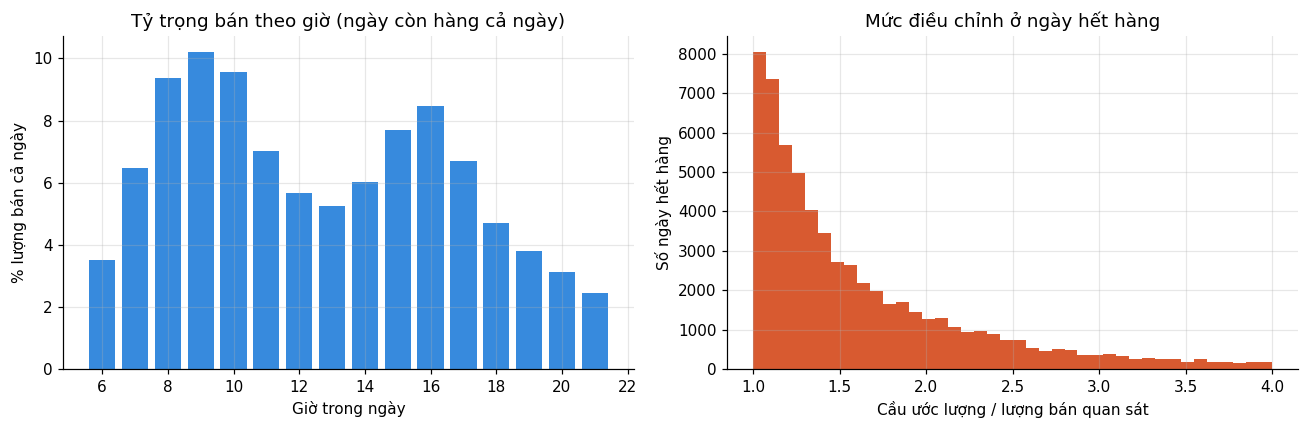

Đã lưu hình: output/eda/data_khoi_phuc_cau.png

NHẬN XÉT — Ngày có hết hàng chiếm 36.3% mẫu; 4.5% số quan sát hết hàng quá sớm nên bị loại. Kiểm chứng trên 30,000 ngày còn hàng giả lập hết hàng: giữ nguyên lượng bán bị chặn lệch -36.2%, hiệu chỉnh theo tỷ trọng giờ chỉ lệch +0.1% (WAPE 27.6% so với 36.2%). Ước tính 15.4% doanh số bị mất do hết hàng. 0 chuỗi dùng tỷ trọng giờ của danh mục vì có ít hơn 5 ngày sạch.


In [17]:
t0 = time.time()
pairs = set(zip(P.store_id.astype(int), P.product_id.astype(int)))
H = load_hourly(pairs)
H["dt"] = pd.to_datetime(H["dt"]); H["key"] = H.store_id.astype(str) + "_" + H.product_id.astype(str)
H = P[["key", "dt"]].merge(H[["key", "dt"] + HOURLY], on=["key", "dt"], how="left")
assert H[HOURLY[0]].notna().all(), "Thiếu dữ liệu theo giờ cho một số quan sát"
S24 = np.array(H.hours_sale.tolist(), dtype=float); O24 = np.array(H.hours_stock_status.tolist(), dtype=float)
del H; gc.collect()
print(f"Dữ liệu theo giờ: {S24.shape} | {time.time()-t0:.0f}s")
S16, O16 = S24[:, 6:22], O24[:, 6:22]
print("Kiểm tra khớp: |tổng theo giờ − sale_amount| trung vị =", np.median(np.abs(S24.sum(1) - P.sale_amount.values)).round(4),
      "| thời lượng hết hàng khớp stock_hour6_22_cnt:", f"{(O16.sum(1) == P.stock_hour6_22_cnt.values).mean():.1%}")

day_out = O16.sum(1) > 0
outside = S24.sum(1) - S16.sum(1)
clean_prof = (~day_out) & (~P.excl.values) & (P.t.values <= T_PROFILE_END)
prof_sum = pd.DataFrame(S16[clean_prof]).groupby(P.key.values[clean_prof]).sum()
n_clean = pd.Series(clean_prof).groupby(P.key.values).sum()
cat_of = P.groupby("key").first_category_id.first()
cat_prof = pd.DataFrame(S16[clean_prof]).groupby(P.first_category_id.values[clean_prof]).sum()
cat_prof = cat_prof.div(cat_prof.sum(1), axis=0)
glob_prof = S16[clean_prof].sum(0) / S16[clean_prof].sum()
PROF = {}
for k in KEYS:
    if n_clean.get(k, 0) >= 5 and k in prof_sum.index and prof_sum.loc[k].sum() > 0:
        PROF[k] = (prof_sum.loc[k] / prof_sum.loc[k].sum()).values
    elif cat_of[k] in cat_prof.index:
        PROF[k] = cat_prof.loc[cat_of[k]].values
    else:
        PROF[k] = glob_prof
n_fallback = sum(1 for k in KEYS if not (n_clean.get(k, 0) >= 5 and k in prof_sum.index))
PR = np.vstack([PROF[k] for k in P.key.values])
cover = (PR * (O16 == 0)).sum(1)
obs16 = S16.sum(1)
low_cover = day_out & (cover < 0.25)
rec = np.where(day_out, obs16 / np.maximum(cover, 1e-9), obs16) + outside
rec = np.where(low_cover, np.nan, rec)
P["obs"] = P.sale_amount.values
P["rec"] = rec
P["cover"] = cover
P["so_hrs"] = O16.sum(1)
P["low_cover"] = low_cover
P["excl"] = P.excl | P.rec.isna()
P["first_out"] = np.where(day_out, O16.argmax(1) + 6, np.nan)

# Kiểm chứng: giả lập hết hàng trên ngày còn hàng cả ngày (6/5–10/6, không dùng để tính tỷ trọng)
rng = np.random.RandomState(CFG["SEED"])
bt = np.where((~day_out) & (~P.excl.values) & (P.t.values > T_PROFILE_END) & (P.t.values <= T_VAL_END) & (obs16 > 0))[0]
bt = rng.choice(bt, size=min(30000, len(bt)), replace=False)
cut = rng.randint(4, 15, size=len(bt))                      # hết hàng giả lập từ 10h đến 20h
mask_cut = np.arange(16)[None, :] < cut[:, None]
est = (S16[bt] * mask_cut).sum(1) / np.maximum((PR[bt] * mask_cut).sum(1), 1e-9)
truth, naive = obs16[bt], (S16[bt] * mask_cut).sum(1)
bt_tab = pd.DataFrame({"Phương pháp": ["Không hiệu chỉnh (giữ lượng bán bị chặn)", "Hiệu chỉnh theo tỷ trọng giờ"],
    "WAPE (%)": [np.abs(naive - truth).sum() / truth.sum() * 100, np.abs(est - truth).sum() / truth.sum() * 100],
    "Sai lệch (%)": [(naive - truth).sum() / truth.sum() * 100, (est - truth).sum() / truth.sum() * 100]}).round(1)
display(bt_tab); savetab(bt_tab, "bang_5_kiem_chung_khoi_phuc", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(6, 22), glob_prof * 100, color="#378ADD"); ax[0].set_xlabel("Giờ trong ngày"); ax[0].set_ylabel("% lượng bán cả ngày")
ax[0].set_title("Tỷ trọng bán theo giờ (ngày còn hàng cả ngày)")
ok = day_out & ~low_cover & (obs16 > 0)
ax[1].hist(np.clip((rec[ok] - outside[ok]) / obs16[ok], 1, 4), bins=40, color="#D85A30")
ax[1].set_xlabel("Cầu ước lượng / lượng bán quan sát"); ax[1].set_ylabel("Số ngày hết hàng"); ax[1].set_title("Mức điều chỉnh ở ngày hết hàng")
savefig("data_khoi_phuc_cau", "Tỷ trọng bán theo giờ và mức điều chỉnh khi ước lượng nhu cầu")
lost = (np.nansum(rec[~P.excl.values]) - P.obs.values[~P.excl.values].sum()) / np.nansum(rec[~P.excl.values])
note("3_khoi_phuc", f"Ngày có hết hàng chiếm {day_out.mean():.1%} mẫu; {low_cover.mean():.1%} số quan sát hết hàng quá sớm nên bị loại. "
     f"Kiểm chứng trên {len(bt):,} ngày còn hàng giả lập hết hàng: giữ nguyên lượng bán bị chặn lệch {bt_tab.iloc[0,2]:+.1f}%, "
     f"hiệu chỉnh theo tỷ trọng giờ chỉ lệch {bt_tab.iloc[1,2]:+.1f}% (WAPE {bt_tab.iloc[1,1]:.1f}% so với {bt_tab.iloc[0,1]:.1f}%). "
     f"Ước tính {lost:.1%} doanh số bị mất do hết hàng. {n_fallback} chuỗi dùng tỷ trọng giờ của danh mục vì có ít hơn 5 ngày sạch.")

**Nhận xét kết quả.** 36,3% số ngày trong mẫu có hết hàng. Kiểm chứng trên 30.000 ngày còn hàng được giả lập hết hàng cho thấy: nếu giữ nguyên lượng bán bị chặn, cầu bị đánh giá thấp **36,2%**; phương pháp hiệu chỉnh theo tỷ trọng giờ gần như không lệch (**+0,1%**), sai số tuyệt đối WAPE giảm từ 36,2% xuống 27,6%. Như vậy phương pháp không tạo sai lệch có hệ thống; sai số còn lại là nhiễu ngẫu nhiên của từng ngày. 4,5% số quan sát hết hàng quá sớm (còn hàng dưới 25% thời lượng bán) bị loại vì không đủ thông tin để ước lượng. Ước tính **15,4% tổng doanh số bị mất vì hết hàng** — một con số lớn đối với doanh nghiệp. Mọi chuỗi đều có đủ ngày sạch để tính tỷ trọng giờ riêng, không cần dùng tỷ trọng chung của danh mục.

## Bước 4A. Khám phá dữ liệu (EDA)

Phần này **chỉ mô tả** dữ liệu — phân phối, trung bình, xu hướng, tương quan — để thấy dữ liệu đang nói gì. Chỉ dùng **train + validation (28/3–10/6)**, không nhìn tập test. Biến nhu cầu là **nhu cầu ước lượng** (`rec`, đã hiệu chỉnh nhu cầu bị kiểm duyệt ở Bước 3); các quan sát bất thường bị loại.

- EDA 0. Tổng quan: phân phối, xu hướng và tương quan
- EDA 1. Khuyến mãi có làm tăng lợi nhuận không?
- EDA 2. Doanh số bị mất do hết hàng
- EDA 3. Thời điểm hết hàng

Phần **đo** tác động của giá bằng hồi quy nằm riêng ở **Bước 4B**. Ô mã dưới đây chuẩn bị dữ liệu dùng chung cho cả 4A và 4B.

In [18]:
E = P[(P.t <= T_VAL_END) & (~P.excl)].copy()
E["log_disc"] = np.log(E.disc); E["depth"] = 1 - E.disc
E["y"] = np.log1p(E.rec)
E["dow"] = E.dt.dt.dayofweek
for k in range(1, 7): E[f"dow{k}"] = (E.dow == k).astype(int)
E["weekend"] = (E.dow >= 5).astype(int)
RAIN_Q = P.loc[P.t <= T_TRAIN_END, "precpt"].quantile(0.75)
E["rain"] = (E.precpt >= RAIN_Q).astype(int)
g = P.groupby("key", sort=False)
P["_ly_src"] = np.log1p(P.rec.fillna(P.obs))
P["_lag1"] = g._ly_src.shift(1)
P["_roll7"] = g._ly_src.transform(lambda x: x.shift(1).rolling(7, min_periods=3).mean())
E = E.join(P[["_lag1", "_roll7"]]).dropna(subset=["_lag1", "_roll7"])

def fe_reg(d, xcols, ycol="y", key="key"):
    Z = d[[ycol] + xcols].astype(float)
    Z = Z - Z.groupby(d[key].values).transform("mean")
    X, y = Z[xcols].values, Z[ycol].values
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    r = y - X @ beta; dof = max(len(y) - len(xcols) - d[key].nunique(), 1)
    se = np.sqrt(np.diag(np.linalg.pinv(X.T @ X)) * (r @ r) / dof)
    return pd.DataFrame({"coef": beta, "se": se}, index=xcols)
CTRL = ["holiday_flag", "rain", "avg_temperature"] + [f"dow{k}" for k in range(1, 7)]
DEPTH_BINS = [-0.001, 0.01, 0.05, 0.10, 0.20, 0.30, 0.50]
DEPTH_LAB = ["0–1%", "1–5%", "5–10%", "10–20%", "20–30%", "30–50%"]
E["depth_bin"] = pd.cut(E.depth, DEPTH_BINS, labels=DEPTH_LAB)
print(f"Dữ liệu EDA: {len(E):,} quan sát, {E.key.nunique():,} chuỗi")

Dữ liệu EDA: 137,688 quan sát, 2,003 chuỗi


### EDA 0. Tổng quan: phân phối, xu hướng và tương quan
Nhìn dữ liệu ở mức cơ bản nhất: thống kê mô tả (trung bình, trung vị, độ lệch chuẩn), phân phối nhu cầu và tỷ lệ chiết khấu, xu hướng tổng nhu cầu theo ngày, khác biệt giữa các danh mục sản phẩm, và ma trận tương quan giữa các biến chính.

,Số quan sát,Trung bình,Độ lệch chuẩn,Nhỏ nhất,Q1,Trung vị,Q3,Lớn nhất
Lượng bán quan sát,137688.0,0.79,0.64,0.00,0.40,0.60,1.00,9.50
Nhu cầu ước lượng,137688.0,0.93,0.81,0.00,0.40,0.70,1.20,15.63
Tỷ lệ chiết khấu (%),137688.0,7.85,10.70,0.00,0.00,1.40,13.10,50.00
"Thời lượng hết hàng (giờ, 0–16)",137688.0,2.01,3.40,0.00,0.00,0.00,4.00,15.00
Lượng mưa,137688.0,1.97,1.04,0.21,1.28,1.78,2.44,5.90
Nhiệt độ (°C),137688.0,20.85,2.77,14.99,18.39,21.00,23.15,26.91


Đã lưu bảng: output/tables/eda0_thong_ke_mo_ta.csv


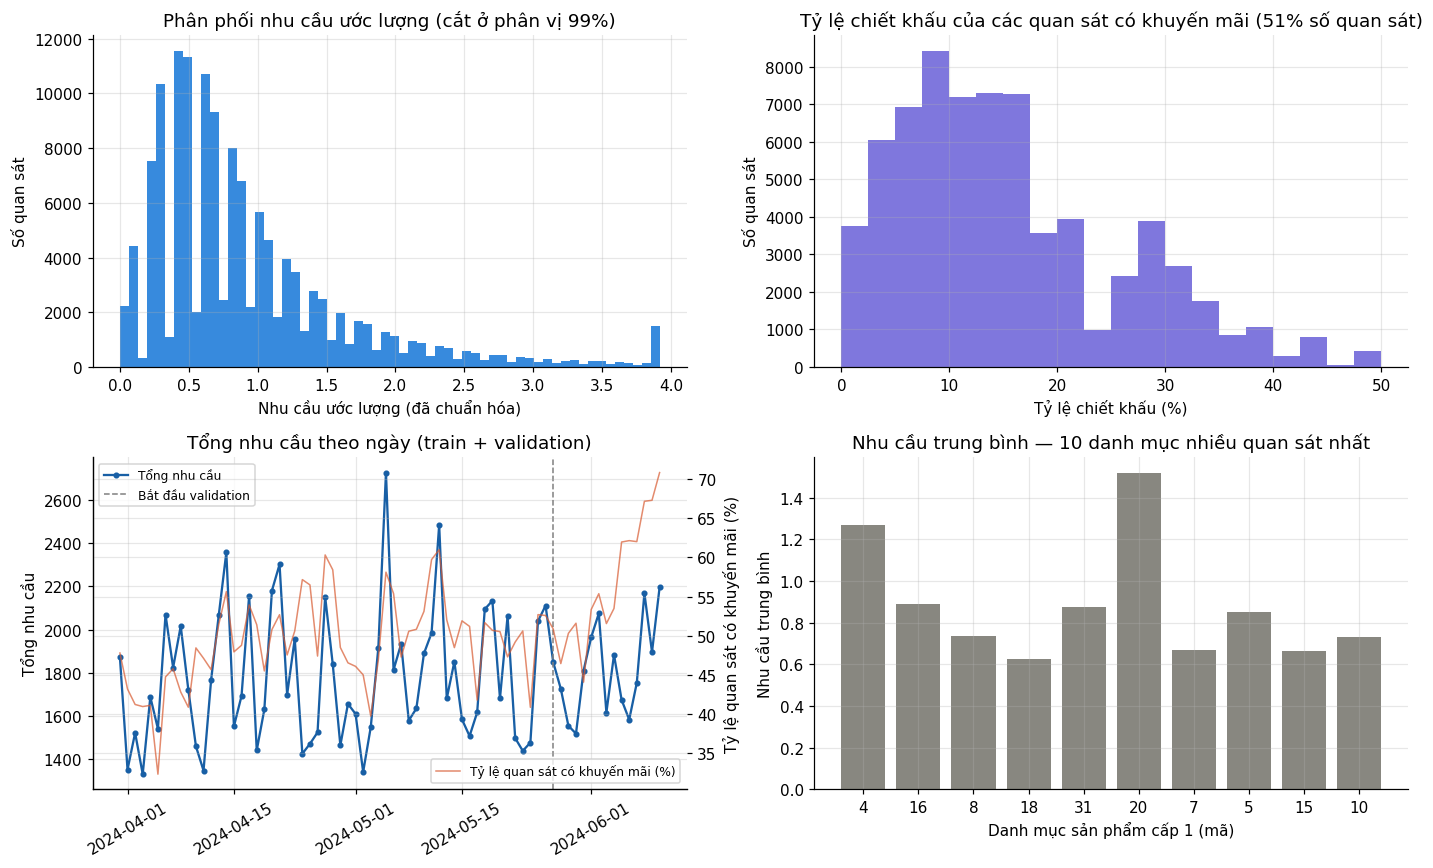

Đã lưu hình: output/eda/eda0_tong_quan.png


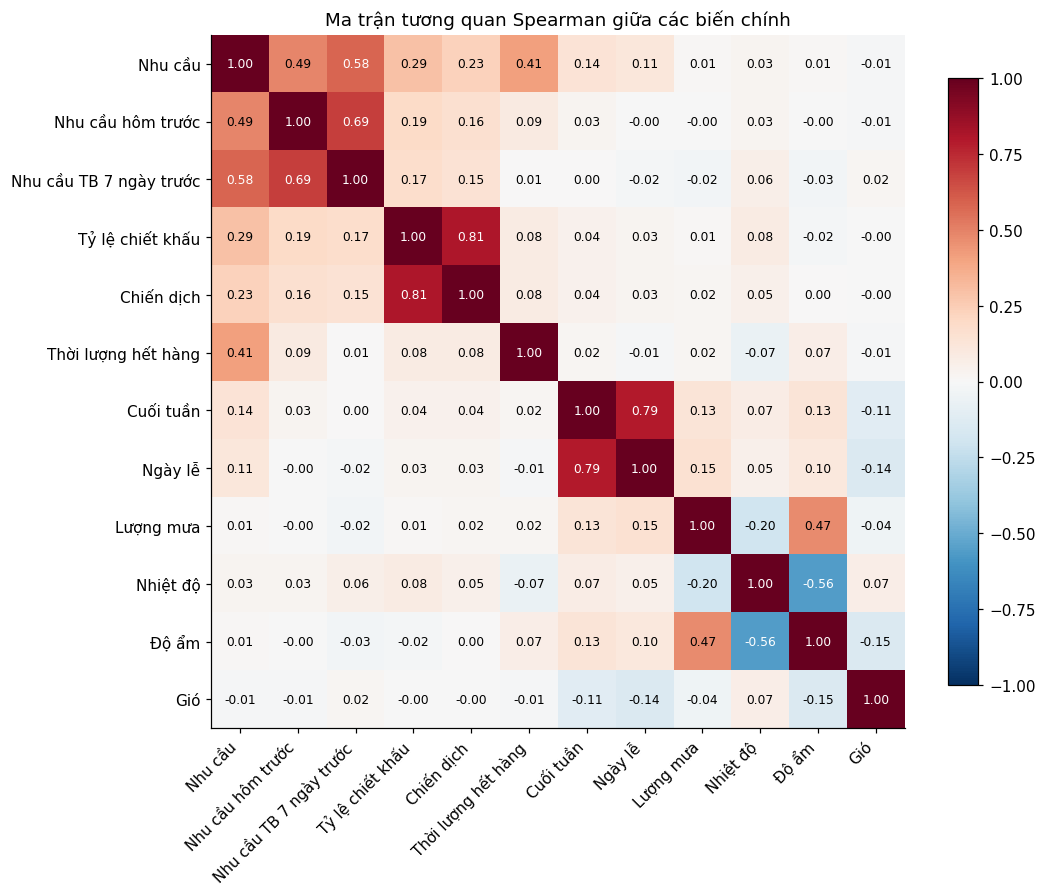

Đã lưu hình: output/eda/eda0_ma_tran_tuong_quan.png
Đã lưu bảng: output/tables/eda0_ma_tran_tuong_quan.csv

NHẬN XÉT — Nhu cầu lệch phải mạnh: trung bình 0.93 nhưng trung vị chỉ 0.70. 51% số quan sát có khuyến mãi, tỷ lệ chiết khấu trung vị 13%; tỷ lệ quan sát có khuyến mãi tăng từ 44% (hai tuần đầu) lên 57% (hai tuần cuối). Tổng nhu cầu hai tuần cuối so với hai tuần đầu thay đổi +7.8%. Tương quan mạnh nhất với nhu cầu là Nhu cầu TB 7 ngày trước (0.58); tỷ lệ chiết khấu 0.29; các biến thời tiết chỉ từ -0.01 đến 0.03.


In [19]:
D = E.copy()
D["chiet_khau"] = (1 - D.disc) * 100

# 1. Thống kê mô tả
desc = pd.DataFrame({"Lượng bán quan sát": D.obs, "Nhu cầu ước lượng": D.rec, "Tỷ lệ chiết khấu (%)": D.chiet_khau,
                     "Thời lượng hết hàng (giờ, 0–16)": D.so_hrs, "Lượng mưa": D.precpt, "Nhiệt độ (°C)": D.avg_temperature}).describe().T
desc = desc[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]].round(2)
desc.columns = ["Số quan sát", "Trung bình", "Độ lệch chuẩn", "Nhỏ nhất", "Q1", "Trung vị", "Q3", "Lớn nhất"]
display(desc); savetab(desc, "eda0_thong_ke_mo_ta")

# 2. Phân phối và xu hướng
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
q99 = D.rec.quantile(0.99)
ax[0, 0].hist(D.rec.clip(upper=q99), bins=60, color="#378ADD")
ax[0, 0].set_title("Phân phối nhu cầu ước lượng (cắt ở phân vị 99%)"); ax[0, 0].set_xlabel("Nhu cầu ước lượng (đã chuẩn hóa)"); ax[0, 0].set_ylabel("Số quan sát")
dg = D[D.is_disc]
ax[0, 1].hist(dg.chiet_khau, bins=np.arange(0, 52.5, 2.5), color="#7F77DD")
ax[0, 1].set_title(f"Tỷ lệ chiết khấu của các quan sát có khuyến mãi ({len(dg)/len(D):.0%} số quan sát)"); ax[0, 1].set_xlabel("Tỷ lệ chiết khấu (%)"); ax[0, 1].set_ylabel("Số quan sát")
daily = D.groupby("dt").agg(cau=("rec", "sum"), km=("is_disc", "mean"))
ax[1, 0].plot(daily.index, daily.cau, color="#185FA5", marker="o", ms=3, label="Tổng nhu cầu")
ax[1, 0].axvline(D.loc[D.t == T_TRAIN_END + 1, "dt"].iloc[0], color="gray", ls="--", lw=1, label="Bắt đầu validation")
ax2 = ax[1, 0].twinx(); ax2.plot(daily.index, daily.km * 100, color="#D85A30", lw=1, alpha=0.7, label="Tỷ lệ quan sát có khuyến mãi (%)"); ax2.set_ylabel("Tỷ lệ quan sát có khuyến mãi (%)")
ax[1, 0].set_title("Tổng nhu cầu theo ngày (train + validation)"); ax[1, 0].set_ylabel("Tổng nhu cầu"); ax[1, 0].legend(loc="upper left", fontsize=8); ax2.legend(loc="lower right", fontsize=8)
ax[1, 0].tick_params(axis="x", rotation=30)
cat = D.groupby("first_category_id").agg(n=("rec", "size"), tb=("rec", "mean")).sort_values("n", ascending=False).head(10)
ax[1, 1].bar(cat.index.astype(str), cat.tb, color="#888780")
ax[1, 1].set_title("Nhu cầu trung bình — 10 danh mục nhiều quan sát nhất"); ax[1, 1].set_xlabel("Danh mục sản phẩm cấp 1 (mã)"); ax[1, 1].set_ylabel("Nhu cầu trung bình")
savefig("eda0_tong_quan", "Tổng quan phân phối và xu hướng")

# 3. Ma trận tương quan (Spearman, vì nhu cầu lệch phải mạnh)
C = pd.DataFrame({"Nhu cầu": D.rec, "Nhu cầu hôm trước": np.expm1(D._lag1), "Nhu cầu TB 7 ngày trước": np.expm1(D._roll7),
                  "Tỷ lệ chiết khấu": D.chiet_khau, "Chiến dịch": D.activity_flag, "Thời lượng hết hàng": D.so_hrs,
                  "Cuối tuần": D.weekend, "Ngày lễ": D.holiday_flag, "Lượng mưa": D.precpt, "Nhiệt độ": D.avg_temperature,
                  "Độ ẩm": D.avg_humidity, "Gió": D.avg_wind_level}).corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(C.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(C))); ax.set_xticklabels(C.columns, rotation=45, ha="right"); ax.set_yticks(range(len(C))); ax.set_yticklabels(C.columns)
for i in range(len(C)):
    for j in range(len(C)):
        ax.text(j, i, f"{C.values[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(C.values[i, j]) > 0.5 else "black")
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Ma trận tương quan Spearman giữa các biến chính"); ax.grid(False)
savefig("eda0_ma_tran_tuong_quan", "Ma trận tương quan")
savetab(C.round(3), "eda0_ma_tran_tuong_quan")

c_n = C["Nhu cầu"].drop("Nhu cầu")
weather = c_n[["Lượng mưa", "Nhiệt độ", "Độ ẩm", "Gió"]]
first, last = daily.cau.iloc[:14].mean(), daily.cau.iloc[-14:].mean()
note("eda0", f"Nhu cầu lệch phải mạnh: trung bình {D.rec.mean():.2f} nhưng trung vị chỉ {D.rec.median():.2f}. "
     f"{len(dg)/len(D):.0%} số quan sát có khuyến mãi, tỷ lệ chiết khấu trung vị {dg.chiet_khau.median():.0f}%; tỷ lệ quan sát có khuyến mãi tăng từ {daily.km.iloc[:14].mean():.0%} (hai tuần đầu) lên {daily.km.iloc[-14:].mean():.0%} (hai tuần cuối). "
     f"Tổng nhu cầu hai tuần cuối so với hai tuần đầu thay đổi {(last/first-1)*100:+.1f}%. "
     f"Tương quan mạnh nhất với nhu cầu là {c_n.abs().idxmax()} ({c_n[c_n.abs().idxmax()]:.2f}); tỷ lệ chiết khấu {c_n['Tỷ lệ chiết khấu']:.2f}; "
     f"các biến thời tiết chỉ từ {weather.min():.2f} đến {weather.max():.2f}.")

**Nhận xét kết quả.**
- **Phân phối nhu cầu lệch phải mạnh**: trung bình 0,93 nhưng trung vị chỉ 0,70 — đa số sản phẩm bán ít, một số ít bán rất chạy. Nhu cầu ước lượng trung bình cao hơn lượng bán quan sát khoảng 18% (0,93 so với 0,79), phần chênh là nhu cầu bị che do hết hàng.
- **Khuyến mãi rất phổ biến**: 51% số quan sát có khuyến mãi, tỷ lệ chiết khấu trung vị 13%, phần lớn dưới 20%. Tỷ lệ quan sát có khuyến mãi **tăng dần theo thời gian** (44% hai tuần đầu → 57% hai tuần cuối), có thể làm giai đoạn test khác với giai đoạn huấn luyện.
- **Xu hướng**: tổng nhu cầu tăng nhẹ (+7,8% giữa hai tuần cuối và hai tuần đầu) và dao động rõ theo chu kỳ tuần.
- **Ma trận tương quan**: biến liên quan mạnh nhất với nhu cầu là nhu cầu trung bình 7 ngày trước (0,58); tỷ lệ chiết khấu tương quan dương (0,29) — chiết khấu càng sâu thì bán càng nhiều; **các biến thời tiết gần như không tương quan** với nhu cầu (−0,01 đến 0,03), nhất quán với kết quả hồi quy ở Bước 4B.

### EDA 1. Giảm giá làm lượng bán tăng bao nhiêu, và bao nhiêu đợt giảm giá thực sự có lời?

Với biên lợi nhuận m = 30%, giảm giá d chỉ hòa vốn khi lượng bán tăng ít nhất **d / (m − d)**. Ví dụ giảm 10% cần bán thêm 50%; giảm 20% cần bán thêm 200%; giảm từ 30% trở lên thì không bao giờ có lời (bán dưới giá vốn). Mức tăng của mỗi ngày giảm giá được so với **trung vị cầu ở các ngày giá gốc của chính chuỗi đó**.

,Số ngày,"Bán tăng (trung vị, %)",Cần tăng để hòa vốn (%),Tỷ lệ ngày có lời (%)
depth_bin,,,,
1–5%,9765,26.3,10.7,62.2
5–10%,15311,27.5,35.7,46.5
10–20%,25251,40.0,84.0,29.4
20–30%,11065,80.9,500.0,11.5
30–50%,7268,100.0,NaN,0.0


Đã lưu bảng: output/tables/eda1_giam_gia_co_loi.csv


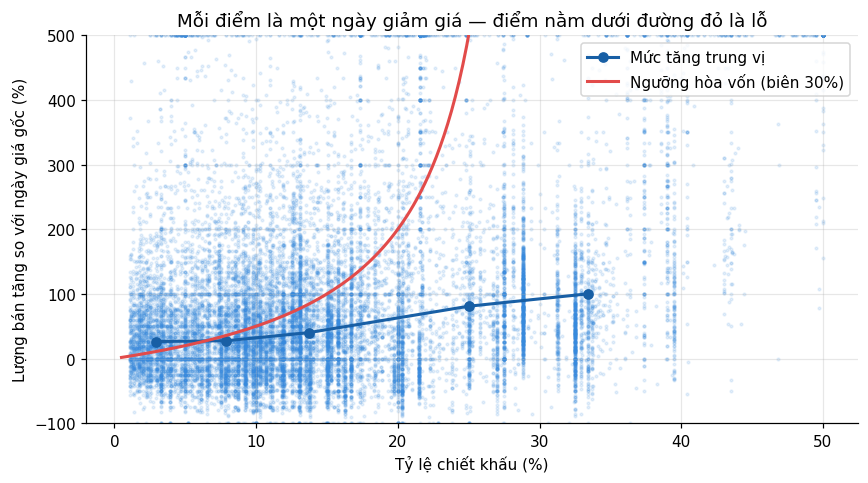

Đã lưu hình: output/eda/eda1_giam_gia_co_loi.png

NHẬN XÉT — Chỉ 32% số ngày giảm giá có lời với biên 30%. Giảm nhẹ 1–5% có lời ở 62% số ngày, còn mức giảm sâu nhất có dữ liệu (30–50%) chỉ có lời ở 0% số ngày. Hàm ý: phần lớn khuyến mãi sâu đang làm giảm lợi nhuận — đây là cơ hội chính của engine.


In [20]:
base = E[~E.is_disc].groupby("key").rec.median().rename("base")
dd = E[E.is_disc].join(base, on="key"); dd = dd[dd.base > 0]
m = CFG["MARGIN"]
dd["lift"] = dd.rec / dd.base - 1
dd["need"] = np.where(dd.depth < m, dd.depth / np.maximum(m - dd.depth, 1e-3), np.inf)
dd["profit"] = dd.lift >= dd.need
t1 = dd.groupby("depth_bin", observed=True).agg(so_ngay=("lift", "size"), tang_trung_vi=("lift", "median"),
                                                can_de_hoa_von=("need", "median"), ty_le_co_loi=("profit", "mean"))
t1[["tang_trung_vi", "can_de_hoa_von", "ty_le_co_loi"]] *= 100
t1 = t1.replace(np.inf, np.nan).round(1)
t1.columns = ["Số ngày", "Bán tăng (trung vị, %)", "Cần tăng để hòa vốn (%)", "Tỷ lệ ngày có lời (%)"]
display(t1); savetab(t1, "eda1_giam_gia_co_loi")
SHARE_OK = dd.profit.mean()
fig, ax = plt.subplots(figsize=(8, 4.5))
smp = dd.sample(min(len(dd), 20000), random_state=0)
ax.scatter(smp.depth * 100, smp.lift.clip(-1, 5) * 100, s=3, alpha=0.12, color="#378ADD")
med = dd.groupby("depth_bin", observed=True).agg(x=("depth", "median"), y=("lift", "median"))
ax.plot(med.x * 100, med.y * 100, "o-", color="#185FA5", lw=2, label="Mức tăng trung vị")
xs = np.linspace(0.005, m - 0.03, 100); ax.plot(xs * 100, xs / (m - xs) * 100, "-", color="#E24B4A", lw=2, label=f"Ngưỡng hòa vốn (biên {m:.0%})")
ax.set_ylim(-100, 500); ax.set_xlabel("Tỷ lệ chiết khấu (%)"); ax.set_ylabel("Lượng bán tăng so với ngày giá gốc (%)")
ax.set_title("Mỗi điểm là một ngày giảm giá — điểm nằm dưới đường đỏ là lỗ"); ax.legend()
savefig("eda1_giam_gia_co_loi", "Mức tăng lượng bán khi giảm giá so với ngưỡng hòa vốn")
note("eda1", f"Chỉ {SHARE_OK:.0%} số ngày giảm giá có lời với biên {m:.0%}. Giảm nhẹ 1–5% có lời ở {t1.iloc[0,3]:.0f}% số ngày, "
     f"còn mức giảm sâu nhất có dữ liệu ({t1.index[-1]}) chỉ có lời ở {t1.iloc[-1,3]:.0f}% số ngày. "
     "Hàm ý: phần lớn khuyến mãi sâu đang làm giảm lợi nhuận — đây là cơ hội chính của engine.")

**Nhận xét kết quả.** Với biên 30%, chỉ **32%** số ngày giảm giá có lượng bán tăng đủ để hòa vốn. Giảm nhẹ 1–5% có lời ở 62% số ngày; giảm từ 30% trở lên không bao giờ có lời vì giá bán thấp hơn giá vốn. Lưu ý đây là so sánh mô tả với mức nền của chính chuỗi, chưa kiểm soát thứ trong tuần hay lịch sử bán, và cầu từng ngày dao động mạnh, nên con số 62% có thể lạc quan. Ước lượng chặt chẽ hơn ở Bước 4B.

### EDA 2. Bao nhiêu doanh số bị mất do hết hàng, tập trung ở đâu?
Doanh số bị mất = cầu ước lượng − lượng bán quan sát. Đây là đầu ra kinh doanh cho bộ phận nhập hàng.

,Số quan sát,Ngày hết hàng (%),Doanh số bị mất (%)
first_category_id,,,
16,15221,39.4,20.3
15,5712,38.5,19.5
27,1177,33.6,18.3
0,1550,33.1,17.7
23,1386,32.5,17.5
24,3947,33.6,17.3
11,1043,33.2,17.2
7,6062,29.5,16.8
18,10631,31.7,16.8


Đã lưu bảng: output/tables/eda4_cau_bi_mat_theo_nganh.csv


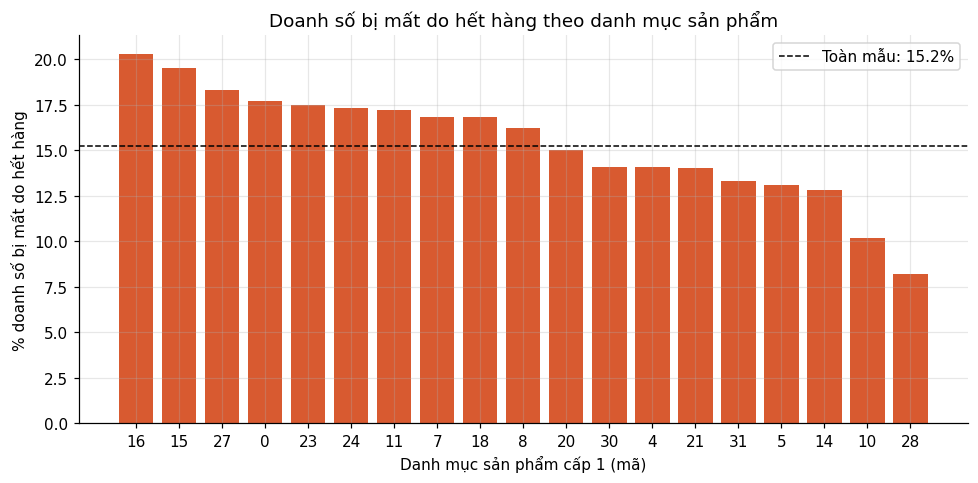

Đã lưu hình: output/eda/eda4_cau_bi_mat.png

NHẬN XÉT — Khoảng 15.2% tổng doanh số bị mất vì hết hàng (train + validation). Danh mục mất nhiều nhất là danh mục 16 (20.3%), ít nhất là danh mục 28 (8.2%). Với những danh mục mất cầu nhiều, đòn bẩy lớn hơn là nhập thêm hàng chứ không phải giảm giá.


In [21]:
E["lost"] = E.rec - E.obs
t4 = E.groupby("first_category_id").agg(so_dong=("rec", "size"), ty_le_ngay_het_hang=("stockout", "mean"),
                                        cau=("rec", "sum"), mat=("lost", "sum"))
t4["ty_le_cau_mat"] = t4.mat / t4.cau
t4 = t4[t4.so_dong >= 500].sort_values("ty_le_cau_mat", ascending=False)
out4 = (t4[["so_dong", "ty_le_ngay_het_hang", "ty_le_cau_mat"]] * [1, 100, 100]).round(1)
out4.columns = ["Số quan sát", "Ngày hết hàng (%)", "Doanh số bị mất (%)"]; display(out4); savetab(out4, "eda4_cau_bi_mat_theo_nganh")
LOST_ALL = E.lost.sum() / E.rec.sum()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(out4.index.astype(str), out4["Doanh số bị mất (%)"], color="#D85A30"); ax.axhline(LOST_ALL * 100, color="k", ls="--", lw=1, label=f"Toàn mẫu: {LOST_ALL:.1%}")
ax.set_xlabel("Danh mục sản phẩm cấp 1 (mã)"); ax.set_ylabel("% doanh số bị mất do hết hàng"); ax.set_title("Doanh số bị mất do hết hàng theo danh mục sản phẩm"); ax.legend()
savefig("eda4_cau_bi_mat", "Tỷ lệ doanh số bị mất do hết hàng theo danh mục")
note("eda4", f"Khoảng {LOST_ALL:.1%} tổng doanh số bị mất vì hết hàng (train + validation). Danh mục mất nhiều nhất là danh mục {out4.index[0]} ({out4.iloc[0,2]:.1f}%), "
     f"ít nhất là danh mục {out4.index[-1]} ({out4.iloc[-1,2]:.1f}%). Với những danh mục mất cầu nhiều, đòn bẩy lớn hơn là nhập thêm hàng chứ không phải giảm giá.")

**Nhận xét kết quả.** Khoảng **15,2%** tổng doanh số bị mất vì hết hàng, khác nhau đáng kể giữa các danh mục: cao nhất danh mục 16 (20,3%), thấp nhất danh mục 28 (8,2%). Với danh mục mất nhiều cầu, giảm giá chỉ làm hàng hết nhanh hơn; đòn bẩy đúng là nhập thêm hàng. Đây là một đầu ra kinh doanh trực tiếp cho bộ phận nhập hàng: danh sách danh mục và cửa hàng cần tăng lượng nhập.

### EDA 3. Hết hàng xảy ra lúc mấy giờ, và giảm giá có làm hết hàng nhiều hơn không?

,Số ngày,Ngày hết hàng (%),Thời lượng hết hàng TB
depth_bin,,,
0–1%,67754,28.86,1.79
1–5%,10017,34.43,2.04
5–10%,15352,35.77,2.22
10–20%,25367,36.24,2.29
20–30%,11242,37.10,2.15
30–50%,7956,40.23,2.35


Đã lưu bảng: output/tables/eda6_het_hang_theo_muc_giam.csv


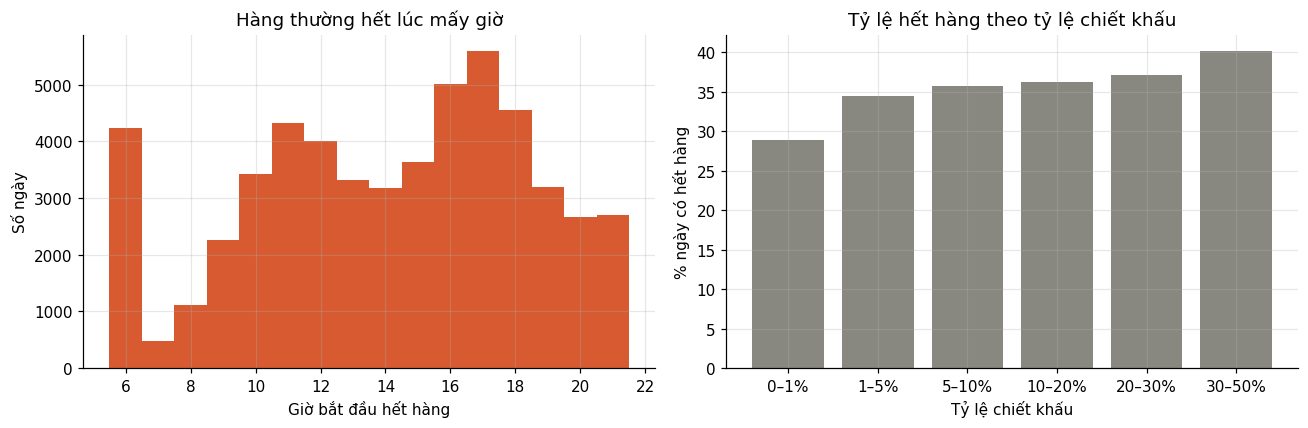

Đã lưu hình: output/eda/eda6_het_hang.png

NHẬN XÉT — Hàng thường bắt đầu hết vào khoảng 15h (trung vị); 35% số ngày hết hàng bắt đầu từ 17h trở đi, còn 8% số ngày hết hàng ngay từ đầu ca (6h), tức hàng không được bổ sung kịp từ hôm trước. Tỷ lệ hết hàng ở ngày giá gốc là 28.9%, ở nhóm giảm sâu nhất (30–50%) là 40.2%: giảm giá làm hết hàng nhiều hơn rõ rệt.


In [22]:
t6 = E.groupby("depth_bin", observed=True).agg(so_ngay=("stockout", "size"), ty_le_het_hang=("stockout", "mean"), gio_het_TB=("so_hrs", "mean"))
t6["ty_le_het_hang"] *= 100; t6 = t6.round(2); t6.columns = ["Số ngày", "Ngày hết hàng (%)", "Thời lượng hết hàng TB"]
display(t6); savetab(t6, "eda6_het_hang_theo_muc_giam")
fo = P.loc[(P.t <= T_VAL_END) & P.first_out.notna(), "first_out"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(fo, bins=np.arange(6, 23) - 0.5, color="#D85A30"); ax[0].set_xlabel("Giờ bắt đầu hết hàng"); ax[0].set_ylabel("Số ngày"); ax[0].set_title("Hàng thường hết lúc mấy giờ")
ax[1].bar(t6.index.astype(str), t6["Ngày hết hàng (%)"], color="#888780"); ax[1].set_xlabel("Tỷ lệ chiết khấu"); ax[1].set_ylabel("% ngày có hết hàng"); ax[1].set_title("Tỷ lệ hết hàng theo tỷ lệ chiết khấu")
savefig("eda6_het_hang", "Thời điểm hết hàng và tỷ lệ hết hàng theo tỷ lệ chiết khấu")
note("eda6", f"Hàng thường bắt đầu hết vào khoảng {fo.median():.0f}h (trung vị); {(fo >= 17).mean():.0%} số ngày hết hàng bắt đầu từ 17h trở đi, còn {(fo <= 6).mean():.0%} số ngày hết hàng ngay từ đầu ca (6h), tức hàng không được bổ sung kịp từ hôm trước. "
     f"Tỷ lệ hết hàng ở ngày giá gốc là {t6.iloc[0,1]:.1f}%, ở nhóm giảm sâu nhất ({t6.index[-1]}) là {t6.iloc[-1,1]:.1f}%: "
     "giảm giá làm hết hàng nhiều hơn " + ("rõ rệt." if t6.iloc[-1,1] - t6.iloc[0,1] > 5 else "không đáng kể — hết hàng chủ yếu do lượng nhập, không do giá."))

**Nhận xét kết quả.** Giờ bắt đầu hết hàng có **hai đỉnh**: một đỉnh ngay lúc mở cửa (6h) — hàng không được bổ sung kịp từ hôm trước — và một đỉnh chiều tối (17–18h) khi cầu cao; trung vị là 15h. Tỷ lệ hết hàng tăng đều theo tỷ lệ chiết khấu, từ 28,9% ở ngày giá gốc lên 40,2% ở nhóm giảm 30–50%. Giảm giá sâu vì vậy gây **thiệt hại kép**: vừa mất biên lợi nhuận trên mỗi đơn vị, vừa làm hàng hết sớm, khiến khách sẵn sàng mua giá gốc vào buổi tối không còn hàng để mua.

## Bước 4B. Đo tác động của giá và bối cảnh

Khác với EDA chỉ mô tả, phần này **ước lượng** tác động bằng **một mô hình hồi quy hiệu ứng cố định (fixed effects)**: so sánh các ngày khác nhau của *cùng một sản phẩm tại cùng một cửa hàng*, có kiểm soát lượng bán những ngày trước đó. Mô hình cho ra cùng lúc:
- **Độ co giãn của cầu theo giá**: giá giảm 1% thì lượng bán tăng bao nhiêu %;
- **Tác động của bối cảnh**: cuối tuần, ngày lễ, mưa nhiều.

Với biên lợi nhuận 30%, muốn một đợt giảm giá nhẹ có lời thì độ co giãn phải mạnh hơn −3,33 (giảm 10% phải bán thêm hơn 33%).

,Yếu tố,Ước lượng,Cách đọc
0,Giá (độ co giãn của cầu theo giá),-0.90,giảm giá 10% thì lượng bán tăng khoảng 10%
1,Cuối tuần (so với ngày thường),+9.2%,thay đổi nhu cầu
2,Ngày lễ,+1.3%,thay đổi nhu cầu
3,"Mưa nhiều (lượng mưa ≥ 2.5, top 25%)",-0.1%,thay đổi nhu cầu


Đã lưu bảng: output/tables/bang_4b_tac_dong_gia_va_boi_canh.csv
Đã lưu bảng: output/tables/bang_4b_do_co_gian_theo_danh_muc.csv


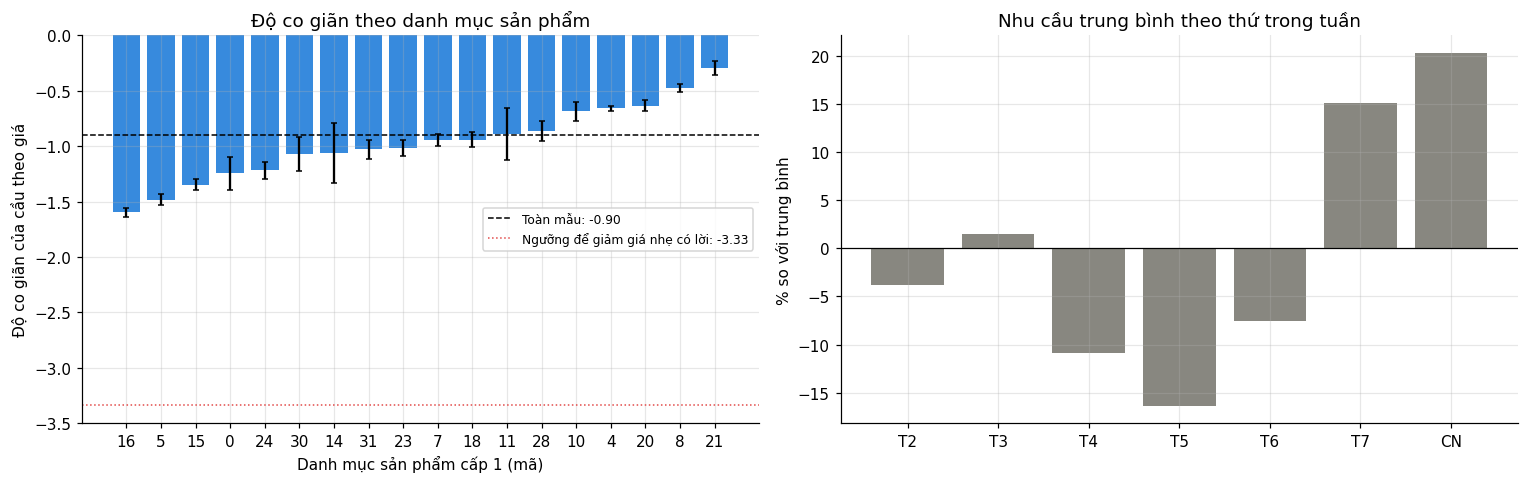

Đã lưu hình: output/eda/eda_4b_tac_dong_gia_va_boi_canh.png
Kiểm tra độ vững (phụ lục):


,Cách ước lượng,Độ co giãn
0,Mô hình chính (bảng trên),-0.90
1,Không kiểm soát lượng bán những ngày trước,-1.00
2,Chỉ dùng khuyến mãi theo chiến dịch,-0.94


Đã lưu bảng: output/tables/phu_luc_do_vung_do_co_gian.csv

NHẬN XÉT — Độ co giãn của cầu theo giá = -0.90: giảm giá 10% thì lượng bán tăng khoảng 10%, không danh mục nào vượt ngưỡng -3.33 (từ -1.60 đến -0.30). Cuối tuần +9.2%, ngày lễ +1.3%, mưa nhiều -0.1%. Đổi cách ước lượng cho độ co giãn từ -1.00 đến -0.90, tức kết quả ổn định.


In [23]:
# Một mô hình hồi quy hiệu ứng cố định: tác động của giá và bối cảnh, có kiểm soát lượng bán những ngày trước
XV = ["log_disc", "_lag1", "_roll7", "weekend", "holiday_flag", "rain", "avg_temperature"]
rM = fe_reg(E, XV)
ELAS = float(rM.loc["log_disc", "coef"])
pct = lambda v: (np.exp(rM.loc[v, "coef"]) - 1) * 100
t4b = pd.DataFrame({
    "Yếu tố": ["Giá (độ co giãn của cầu theo giá)", "Cuối tuần (so với ngày thường)", "Ngày lễ", f"Mưa nhiều (lượng mưa ≥ {RAIN_Q:.1f}, top 25%)"],
    "Ước lượng": [f"{ELAS:.2f}", f"{pct('weekend'):+.1f}%", f"{pct('holiday_flag'):+.1f}%", f"{pct('rain'):+.1f}%"],
    "Cách đọc": [f"giảm giá 10% thì lượng bán tăng khoảng {(0.9 ** ELAS - 1) * 100:.0f}%", "thay đổi nhu cầu", "thay đổi nhu cầu", "thay đổi nhu cầu"]})
display(t4b); savetab(t4b, "bang_4b_tac_dong_gia_va_boi_canh", index=False)

# Độ co giãn theo danh mục sản phẩm (cùng mô hình, chạy riêng từng danh mục)
rows = []
for c, gdf in E.groupby("first_category_id"):
    if gdf.is_disc.sum() < 300 or (~gdf.is_disc).sum() < 300: continue
    r = fe_reg(gdf, XV)
    rows.append({"danh_muc": int(c), "so_quan_sat": len(gdf), "do_co_gian": r.loc["log_disc", "coef"], "se": r.loc["log_disc", "se"]})
ELAS_CAT = pd.DataFrame(rows).sort_values("do_co_gian").reset_index(drop=True)
savetab(ELAS_CAT.round(3), "bang_4b_do_co_gian_theo_danh_muc", index=False)
dow_eff = E.groupby("dow").rec.mean() / E.rec.mean() * 100 - 100
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(ELAS_CAT.danh_muc.astype(str), ELAS_CAT.do_co_gian, yerr=1.96 * ELAS_CAT.se, color="#378ADD", capsize=2)
ax[0].axhline(ELAS, color="k", lw=1, ls="--", label=f"Toàn mẫu: {ELAS:.2f}")
ax[0].axhline(-1 / m, color="#E24B4A", lw=1, ls=":", label=f"Ngưỡng để giảm giá nhẹ có lời: {-1/m:.2f}")
ax[0].set_xlabel("Danh mục sản phẩm cấp 1 (mã)"); ax[0].set_ylabel("Độ co giãn của cầu theo giá"); ax[0].set_title("Độ co giãn theo danh mục sản phẩm"); ax[0].legend(fontsize=8)
ax[1].bar(["T2", "T3", "T4", "T5", "T6", "T7", "CN"], dow_eff.values, color="#888780"); ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_ylabel("% so với trung bình"); ax[1].set_title("Nhu cầu trung bình theo thứ trong tuần")
savefig("eda_4b_tac_dong_gia_va_boi_canh", "Tác động của giá và bối cảnh")

# Kiểm tra độ vững (đưa vào phụ lục): đổi cách ước lượng, độ co giãn có đổi không?
rA = fe_reg(E, ["log_disc"] + CTRL)
EC = E[(E.activity_flag == 1) | (~E.is_disc)]
rC = fe_reg(EC, ["log_disc", "_lag1", "_roll7"] + CTRL)
rob = pd.DataFrame({"Cách ước lượng": ["Mô hình chính (bảng trên)", "Không kiểm soát lượng bán những ngày trước", "Chỉ dùng khuyến mãi theo chiến dịch"],
                    "Độ co giãn": [ELAS, rA.loc["log_disc", "coef"], rC.loc["log_disc", "coef"]]}).round(2)
print("Kiểm tra độ vững (phụ lục):"); display(rob); savetab(rob, "phu_luc_do_vung_do_co_gian", index=False)

note("4b", f"Độ co giãn của cầu theo giá = {ELAS:.2f}: giảm giá 10% thì lượng bán tăng khoảng {(0.9 ** ELAS - 1) * 100:.0f}%, "
     f"không danh mục nào vượt ngưỡng {-1/m:.2f} (từ {ELAS_CAT.do_co_gian.min():.2f} đến {ELAS_CAT.do_co_gian.max():.2f}). "
     f"Cuối tuần {pct('weekend'):+.1f}%, ngày lễ {pct('holiday_flag'):+.1f}%, mưa nhiều {pct('rain'):+.1f}%. "
     f"Đổi cách ước lượng cho độ co giãn từ {rob['Độ co giãn'].min():.2f} đến {rob['Độ co giãn'].max():.2f}, tức kết quả ổn định.")

**Nhận xét kết quả.** Độ co giãn của cầu theo giá là **−0,90**: giảm giá 10% thì lượng bán tăng khoảng 10%. Với biên lợi nhuận 30%, mỗi đơn vị bán ra mất 1/3 tiền lời khi giảm 10%, nên cần bán thêm 50% mới hòa vốn — trong khi thực tế chỉ bán thêm khoảng 10%. Theo danh mục sản phẩm, độ co giãn từ −1,60 đến −0,30, **không danh mục nào đạt ngưỡng −3,33**. **Hàm ý kinh doanh:** khuyến mãi làm tăng doanh số nhưng giảm lợi nhuận gộp; engine nên giảm giá nông hơn và ít ngày hơn.

Về bối cảnh: **cuối tuần làm nhu cầu tăng 9,2%**, trong khi ngày lễ (+1,3%) và mưa nhiều (−0,1%) gần như không ảnh hưởng. Tín hiệu nhu cầu cao mà engine dùng để rút bớt khuyến mãi vì vậy chủ yếu là **ngày trong tuần**, không phải thời tiết.

Kiểm tra độ vững (phụ lục): khi bỏ kiểm soát lượng bán những ngày trước, hoặc chỉ dùng khuyến mãi theo chiến dịch, độ co giãn vẫn trong khoảng −1,00 đến −0,90 — kết quả ổn định.

## Bước 5. Tạo đặc trưng

Mọi đặc trưng tại ngày t chỉ dùng thông tin **biết được vào sáng ngày t** (khi engine ra quyết định giá):

| Nhóm | Đặc trưng | Ghi chú |
|---|---|---|
| Giá (engine điều khiển) | `log_disc` (log mức giá hôm nay), `disc_chg` (thay đổi so với hôm qua), `run_prev` (số ngày đã giảm liên tiếp đến hôm qua), `activity_flag` | Khi định giá, engine chỉ thay `log_disc` và `disc_chg` |
| Lịch sử cầu | `lag1`, `lag2`, `lag7`, `roll7`, `roll14`, `std7`, `lvl` (trung bình tích lũy đến hôm qua), `so_lag1` (giờ hết hàng hôm qua / 16) | Kiểm soát việc giảm giá sau ngày bán chậm; `lvl` thay cho mức trung bình toàn kỳ để tránh rò rỉ |
| Bối cảnh | `holiday_flag`, lượng mưa, nhiệt độ, độ ẩm, gió, thứ trong tuần, danh mục sản phẩm | Thời tiết dùng như dự báo thời tiết có sẵn vào buổi sáng |

**Biến mục tiêu:** `y = log(1 + nhu cầu ước lượng)`. Một bộ đặc trưng thứ hai được tạo từ **lượng bán quan sát** để so sánh ở cuối bước 6.

In [24]:
def a2(col): return P[col].values.reshape(S_N, T_N).astype(float)
def shift2(a, k): o = np.full_like(a, np.nan); o[:, k:] = a[:, :-k]; return o
def roll2(a, w, fn="mean", minp=3):
    r = pd.DataFrame(a.T).rolling(w, min_periods=minp)
    return (r.mean() if fn == "mean" else r.std()).T.values
DOW = P.dt.dt.dayofweek.values
CATS = sorted(P.first_category_id.unique())

def build_features(src_col):
    ls = np.log1p(a2(src_col))                  # log cầu (đã hiệu chỉnh hoặc gốc)
    sh = shift2(ls, 1)
    F = {}
    ld = np.log(np.clip(a2("disc"), 1 - CFG["MAX_DEPTH"], 1.0)); ldl1 = shift2(ld, 1)   # quan sát bất thường được cắt về khoảng hợp lệ
    d = a2("is_disc"); run = np.zeros_like(d)
    for t in range(1, T_N): run[:, t] = np.where(d[:, t-1] > 0, run[:, t-1] + 1, 0)
    F["log_disc"], F["disc_chg"], F["run_prev"], F["activity_flag"] = ld, ld - ldl1, run, a2("activity_flag")
    F["lag1"], F["lag2"], F["lag7"] = sh, shift2(ls, 2), shift2(ls, 7)
    F["roll7"], F["roll14"], F["std7"] = roll2(sh, 7), roll2(sh, 14), roll2(sh, 7, "std")
    F["lvl"] = pd.DataFrame(sh.T).expanding(min_periods=3).mean().T.values
    F["so_lag1"] = shift2(a2("so_hrs") / 16, 1)
    for c in ["holiday_flag", "precpt", "avg_temperature", "avg_humidity", "avg_wind_level"]: F[c] = a2(c)
    X = pd.DataFrame({k: v.ravel() for k, v in F.items()})
    for k in range(1, 7): X[f"dow{k}"] = (DOW == k).astype(float)
    for c in CATS: X[f"cat_{c}"] = (P.first_category_id.values == c).astype(float)
    return X, ldl1.ravel(), ls

In [25]:
P["rec_src"] = P.rec.fillna(P.obs)          # dùng cho lag; quan sát bị loại vẫn cung cấp lịch sử
X_rec, LDL1, LS_REC = build_features("rec_src")
X_raw, _, LS_RAW = build_features("obs")
FEATS = list(X_rec.columns)
Y_REC = np.log1p(P.rec.values); Y_RAW = np.log1p(P.obs.values)
TT = P.t.values; USABLE = (~P.excl.values) & (TT >= T_WARM) & np.isfinite(Y_REC)
def rows(t_from, t_to, extra=None):
    m = USABLE & (TT >= t_from) & (TT <= t_to)
    if extra is not None: m &= extra
    return np.where(m)[0]
IDX_TR, IDX_VA, IDX_TE = rows(T_WARM, T_TRAIN_END), rows(T_TRAIN_END + 1, T_VAL_END), rows(T_VAL_END + 1, T_END)
IDX_DEV = rows(T_WARM, T_VAL_END)
X_rec = X_rec.replace([np.inf, -np.inf], np.nan); X_raw = X_raw.replace([np.inf, -np.inf], np.nan)
med_fill = X_rec.iloc[IDX_TR].median()
X_rec = X_rec.fillna(med_fill); X_raw = X_raw.fillna(X_raw.iloc[IDX_TR].median())
XR, XW = X_rec.values.astype(np.float32), X_raw.values.astype(np.float32)
I_LD, I_DC = FEATS.index("log_disc"), FEATS.index("disc_chg")
ft = pd.DataFrame({"Nhóm": ["Giá"] * 4 + ["Lịch sử cầu"] * 8 + ["Bối cảnh"] * (len(FEATS) - 12), "Đặc trưng": FEATS})
print(f"{len(FEATS)} đặc trưng | train {len(IDX_TR):,} · validation {len(IDX_VA):,} · test {len(IDX_TE):,} quan sát")
savetab(ft, "bang_6_dac_trung", index=False)
corr = pd.Series({c: np.corrcoef(X_rec[c].values[IDX_TR], Y_REC[IDX_TR])[0, 1] for c in FEATS[:20]}).sort_values()
note("5_dac_trung", f"{len(FEATS)} đặc trưng ({len(CATS)} danh mục sản phẩm mã hóa one-hot). Tương quan mạnh nhất với cầu là {corr.abs().idxmax()} ({corr[corr.abs().idxmax()]:.2f}); "
     f"tương quan thô của log_disc là {corr['log_disc']:.2f} — " + ("âm, đúng chiều." if corr['log_disc'] < 0 else "gần 0 hoặc dương do giảm giá xảy ra sau ngày bán chậm, nên mô hình cần lịch sử bán để tách tác động thật của giá."))

51 đặc trưng | train 88,005 · validation 28,851 · test 41,984 quan sát
Đã lưu bảng: output/tables/bang_6_dac_trung.csv

NHẬN XÉT — 51 đặc trưng (28 danh mục sản phẩm mã hóa one-hot). Tương quan mạnh nhất với cầu là roll14 (0.65); tương quan thô của log_disc là -0.35 — âm, đúng chiều.


**Nhận xét kết quả.** Có 51 đặc trưng (28 danh mục sản phẩm mã hóa one-hot), chia thành train 88.005 · validation 28.851 · test 41.984 quan sát. Trung bình cầu 14 ngày trước (`roll14`) có tương quan mạnh nhất với cầu (0,65). Tương quan thô của mức giá hôm nay là −0,35, âm đúng chiều: ngày giá thấp hơn đi kèm cầu cao hơn.

## Bước 6. Dự báo cầu bằng 5 mô hình

**Quy trình 3 lớp:**
1. **Time-series CV trong train** (cửa sổ mở rộng, 3 fold × 7 ngày: kiểm tra 6–12/5, 13–19/5, 20–26/5) → chọn tham số bên trong từng mô hình.
2. **Validation 27/5–10/6** → hệ số hiệu chỉnh, trọng số Hybrid, kiểm tra độ nhạy giá, **chọn mô hình dùng cho engine**.
3. **Huấn luyện lại trên train + validation → chấm test 11/6–2/7 một lần.**

**Chỉ số** (trên thang cầu, sau khi đổi ngược từ log): WAPE = Σ|sai số| / Σ cầu thật (chỉ số chính, dễ hiểu theo %), MAE, RMSE, R², và Bias = Σ(dự báo − thật)/Σ thật (dương = dự báo thừa).

**Mô hình:** Linear Regression (Ridge) · Random Forest · XGBoost (ràng buộc đơn điệu: giá tăng thì cầu không tăng) · LSTM (14 ngày lịch sử + đặc trưng hôm nay) · Hybrid RF+LSTM.

In [26]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb, torch, torch.nn as nn, joblib
torch.set_num_threads(max(1, os.cpu_count() or 1)); torch.manual_seed(CFG["SEED"])
REC_ACT = P.rec.values

def metrics(q_hat, idx, actual=None):
    a = REC_ACT[idx] if actual is None else actual
    e = q_hat - a
    return dict(WAPE=np.abs(e).sum() / a.sum() * 100, MAE=np.abs(e).mean(), RMSE=np.sqrt((e ** 2).mean()),
                R2=1 - (e ** 2).sum() / ((a - a.mean()) ** 2).sum(), Bias=e.sum() / a.sum() * 100)

def with_price(X, idx, level):
    Z = X[idx].copy()
    if level is not None:
        Z[:, I_LD] = np.log(level); Z[:, I_DC] = np.log(level) - np.nan_to_num(LDL1[idx], nan=0.0)
    return Z

class Tab:
    # Bọc mô hình dạng bảng: fit trên log-cầu, dự báo trả về log-cầu
    def __init__(self, kind, params, X=XR, Y=Y_REC): self.kind, self.params, self.X, self.Y = kind, params, X, Y
    def fit(self, idx):
        if self.kind == "LR": self.m = make_pipeline(StandardScaler(), Ridge(**self.params))
        elif self.kind == "RF": self.m = RandomForestRegressor(n_estimators=150 if not CFG["FAST"] else 60, max_features=0.5, max_samples=0.7,
                                                               n_jobs=-1, random_state=CFG["SEED"], **self.params)
        elif self.kind == "XGB":
            mono = tuple(-1 if f in ("log_disc", "disc_chg") else 0 for f in FEATS)
            self.m = xgb.XGBRegressor(n_estimators=500 if not CFG["FAST"] else 200, subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                                      monotone_constraints=mono, n_jobs=-1, random_state=CFG["SEED"], **self.params)
        self.m.fit(self.X[idx], self.Y[idx]); return self
    def predict(self, idx, level=None): return self.m.predict(with_price(self.X, idx, level))

In [27]:
SEQ_COLS = ["rec_src", "disc", "so_hrs", "activity_flag", "holiday_flag"]
def build_seq(src="rec_src"):
    arrs = []
    for c in SEQ_COLS:
        a = a2(src if c == "rec_src" else c)
        arrs.append(np.log1p(a) if c == "rec_src" else (np.log(np.clip(a, 1 - CFG["MAX_DEPTH"], 1.0)) if c == "disc" else (a / 16 if c == "so_hrs" else a)))
    return np.stack(arrs, -1).astype(np.float32)
SEQ = build_seq()
L = CFG["SEQ_LEN"]

class LSTMNet(nn.Module):
    def __init__(self, fs, ft, h, drop):
        super().__init__(); self.lstm = nn.LSTM(fs, h, batch_first=True)
        self.head = nn.Sequential(nn.Linear(h + ft, 64), nn.ReLU(), nn.Dropout(drop), nn.Linear(64, 1))
    def forward(self, xs, xt):
        _, (h, _) = self.lstm(xs); return self.head(torch.cat([h[-1], xt], 1)).squeeze(1)

class LSTMModel:
    def __init__(self, params, X=XR, Y=Y_REC, seq=SEQ): self.p, self.X, self.Y, self.seq = params, X, Y, seq
    def _seq(self, idx):
        s, t = idx // T_N, idx % T_N
        return self.seq[s[:, None], t[:, None] + np.arange(-L, 0)[None, :]]
    def _tensors(self, idx, level=None):
        xs = (self._seq(idx) - self.sm) / self.ss; xt = (with_price(self.X, idx, level) - self.tm) / self.ts
        return torch.from_numpy(xs.astype(np.float32)), torch.from_numpy(xt.astype(np.float32))
    def fit(self, idx):
        torch.manual_seed(CFG["SEED"])
        sq = self._seq(idx).reshape(-1, len(SEQ_COLS)); self.sm, self.ss = sq.mean(0), sq.std(0) + 1e-6
        self.tm, self.ts = self.X[idx].mean(0), self.X[idx].std(0) + 1e-6
        self.ym, self.ys = self.Y[idx].mean(), self.Y[idx].std()
        self.net = LSTMNet(len(SEQ_COLS), self.X.shape[1], self.p["hidden"], self.p["dropout"])
        opt = torch.optim.Adam(self.net.parameters(), lr=self.p["lr"]); lossf = nn.MSELoss()
        xs, xt = self._tensors(idx); y = torch.from_numpy(((self.Y[idx] - self.ym) / self.ys).astype(np.float32))
        n = len(idx); epochs = self.p.get("epochs", 6 if CFG["FAST"] else 12)
        for ep in range(epochs):
            self.net.train(); perm = torch.randperm(n)
            for b in range(0, n, 512):
                j = perm[b:b + 512]; opt.zero_grad(); loss = lossf(self.net(xs[j], xt[j]), y[j]); loss.backward(); opt.step()
        return self
    def predict(self, idx, level=None):
        self.net.eval(); out = []
        with torch.no_grad():
            for b in range(0, len(idx), 8192):
                xs, xt = self._tensors(idx[b:b + 8192], level); out.append(self.net(xs, xt).numpy())
        return np.concatenate(out) * self.ys + self.ym

class Hybrid:
    def __init__(self, rf, lstm, alpha): self.rf, self.lstm, self.alpha = rf, lstm, alpha
    def predict(self, idx, level=None):
        return np.log1p(self.alpha * np.expm1(self.rf.predict(idx, level)) + (1 - self.alpha) * np.expm1(self.lstm.predict(idx, level)))
print("Đã khai báo 5 mô hình.")

Đã khai báo 5 mô hình.


### 6.1 Time-series CV trong train — chọn tham số cho từng mô hình

In [28]:
GRIDS = {
    "LR":  [{"alpha": a} for a in [0.1, 1.0, 10.0]],
    "RF":  [{"max_depth": d, "min_samples_leaf": l} for d in [12, None] for l in [5, 20]],
    "XGB": [{"max_depth": d, "learning_rate": lr} for d in [4, 6] for lr in [0.05, 0.1]],
}
lstm_space = [{"hidden": h, "lr": lr, "dropout": dp} for h in [32, 64] for lr in [1e-3, 3e-3] for dp in [0.1, 0.2]]
GRIDS["LSTM"] = random.Random(CFG["SEED"]).sample(lstm_space, 4)        # random search, không lặp cấu hình
if CFG["FAST"]: GRIDS = {k: v[:2] for k, v in GRIDS.items()}

def make(kind, params, X=XR, Y=Y_REC, seq=SEQ):
    return LSTMModel(params, X, Y, seq) if kind == "LSTM" else Tab(kind, params, X, Y)
CV_ROWS, BEST = [], {}
for kind, grid in GRIDS.items():
    t0 = time.time()
    for params in grid:
        scores = []
        for (a, b) in FOLDS:
            tr_i, va_i = rows(T_WARM, a - 1), rows(a, b)
            mdl = make(kind, params).fit(tr_i)
            scores.append(metrics(np.clip(np.expm1(mdl.predict(va_i)), 0, None), va_i)["WAPE"])
        CV_ROWS.append({"Mô hình": kind, "Tham số": json.dumps(params), "WAPE CV TB (%)": np.mean(scores), "Độ lệch giữa fold": np.std(scores)})
    sub = [r for r in CV_ROWS if r["Mô hình"] == kind]
    BEST[kind] = json.loads(min(sub, key=lambda r: r["WAPE CV TB (%)"])["Tham số"])
    print(f"{kind}: xong {len(grid)} cấu hình × {len(FOLDS)} fold sau {time.time()-t0:.0f}s → chọn {BEST[kind]}")
CV_TAB = pd.DataFrame(CV_ROWS).round(2); display(CV_TAB); savetab(CV_TAB, "bang_7_cv_tham_so", index=False)
spread = CV_TAB.groupby("Mô hình")["WAPE CV TB (%)"].agg(lambda s: s.max() - s.min())
note("6_1_cv", "Tham số được chọn theo WAPE trung bình 3 fold: " + "; ".join(f"{k} {v}" for k, v in BEST.items()) +
     f". Chênh lệch WAPE giữa cấu hình tốt nhất và kém nhất của mỗi mô hình: " + ", ".join(f"{k} {v:.2f} điểm" for k, v in spread.items()) +
     ". Độ lệch giữa các fold cho biết mức dao động tự nhiên — chênh lệch tham số nhỏ hơn mức này thì không đáng kể.")

LR: xong 3 cấu hình × 3 fold sau 3s → chọn {'alpha': 10.0}
RF: xong 4 cấu hình × 3 fold sau 615s → chọn {'max_depth': 12, 'min_samples_leaf': 5}
XGB: xong 4 cấu hình × 3 fold sau 78s → chọn {'max_depth': 4, 'learning_rate': 0.05}
LSTM: xong 4 cấu hình × 3 fold sau 647s → chọn {'hidden': 64, 'lr': 0.001, 'dropout': 0.2}


,Mô hình,Tham số,WAPE CV TB (%),Độ lệch giữa fold
0,LR,"{""alpha"": 0.1}",37.96,0.33
1,LR,"{""alpha"": 1.0}",37.96,0.33
2,LR,"{""alpha"": 10.0}",37.96,0.33
3,RF,"{""max_depth"": 12, ""min_samples_leaf"": 5}",36.82,0.48
4,RF,"{""max_depth"": 12, ""min_samples_leaf"": 20}",37.09,0.57
5,RF,"{""max_depth"": null, ""min_samples_leaf"": 5}",36.84,0.42
6,RF,"{""max_depth"": null, ""min_samples_leaf"": 20}",37.08,0.58
7,XGB,"{""max_depth"": 4, ""learning_rate"": 0.05}",36.61,0.91
8,XGB,"{""max_depth"": 4, ""learning_rate"": 0.1}",37.09,1.14
9,XGB,"{""max_depth"": 6, ""learning_rate"": 0.05}",36.80,1.00


Đã lưu bảng: output/tables/bang_7_cv_tham_so.csv

NHẬN XÉT — Tham số được chọn theo WAPE trung bình 3 fold: LR {'alpha': 10.0}; RF {'max_depth': 12, 'min_samples_leaf': 5}; XGB {'max_depth': 4, 'learning_rate': 0.05}; LSTM {'hidden': 64, 'lr': 0.001, 'dropout': 0.2}. Chênh lệch WAPE giữa cấu hình tốt nhất và kém nhất của mỗi mô hình: LR 0.00 điểm, LSTM 0.86 điểm, RF 0.27 điểm, XGB 0.92 điểm. Độ lệch giữa các fold cho biết mức dao động tự nhiên — chênh lệch tham số nhỏ hơn mức này thì không đáng kể.


**Nhận xét kết quả.** Tham số được chọn: Linear Regression α = 10; Random Forest độ sâu 12, tối thiểu 5 mẫu mỗi lá; XGBoost độ sâu 4, tốc độ học 0,05; LSTM 64 nơ-ron, tốc độ học 0,001, dropout 0,2. Chênh lệch WAPE giữa cấu hình tốt nhất và kém nhất của mỗi mô hình chỉ 0–0,9 điểm, tức kết quả không nhạy với tham số trong phạm vi đã thử. Random Forest tốn thời gian nhất (khoảng 10 phút cho 12 lần huấn luyện trên CPU), XGBoost nhanh hơn khoảng 7 lần.

### 6.2 Huấn luyện trên train, đánh giá trên validation, hiệu chỉnh và ghép Hybrid
Mô hình học trên thang log nên khi đổi ngược thường dự báo hơi thấp. **Hệ số hiệu chỉnh** c = Σ cầu thật / Σ dự báo trên validation sửa sai lệch này. Trọng số α của Hybrid (α·RF + (1−α)·LSTM) cũng chọn trên validation.

In [29]:
t0 = time.time()
M_TR = {k: make(k, BEST[k]).fit(IDX_TR) for k in ["LR", "RF", "XGB", "LSTM"]}
print(f"Huấn luyện trên train xong sau {time.time()-t0:.0f}s")
q_va_raw = {k: np.clip(np.expm1(m.predict(IDX_VA)), 0, None) for k, m in M_TR.items()}
best_a, best_w = 0.5, 1e9
for a in np.round(np.arange(0, 1.01, 0.1), 1):
    w = metrics(a * q_va_raw["RF"] + (1 - a) * q_va_raw["LSTM"], IDX_VA)["WAPE"]
    if w < best_w: best_a, best_w = a, w
M_TR["Hybrid"] = Hybrid(M_TR["RF"], M_TR["LSTM"], best_a)
q_va_raw["Hybrid"] = best_a * q_va_raw["RF"] + (1 - best_a) * q_va_raw["LSTM"]
CAL = {k: REC_ACT[IDX_VA].sum() / max(q.sum(), 1e-9) for k, q in q_va_raw.items()}
VA_TAB = pd.DataFrame({k: metrics(q * CAL[k], IDX_VA) for k, q in q_va_raw.items()}).T.drop(columns="Bias").round(3)   # bias = 0 do đã hiệu chỉnh trên chính tập này
VA_TAB["Hệ số hiệu chỉnh"] = pd.Series(CAL).round(3)
NAMES = {"LR": "Linear Regression", "RF": "Random Forest", "XGB": "XGBoost", "LSTM": "LSTM", "Hybrid": "Hybrid RF+LSTM"}
VA_TAB.index = [NAMES[k] for k in VA_TAB.index]; display(VA_TAB); savetab(VA_TAB, "bang_8_validation")
note("6_2_validation", f"Trên validation, WAPE thấp nhất là {VA_TAB.WAPE.idxmin()} ({VA_TAB.WAPE.min():.2f}%), cao nhất là {VA_TAB.WAPE.idxmax()} ({VA_TAB.WAPE.max():.2f}%). "
     f"Hybrid chọn α = {best_a} (trọng số của Random Forest). Hệ số hiệu chỉnh nằm trong khoảng {min(CAL.values()):.2f}–{max(CAL.values()):.2f}.")

Huấn luyện trên train xong sau 193s


,WAPE,MAE,RMSE,R2,Hệ số hiệu chỉnh
Linear Regression,38.085,0.360,0.528,0.557,1.135
Random Forest,36.223,0.342,0.495,0.611,1.069
XGBoost,36.027,0.341,0.490,0.618,1.065
LSTM,36.032,0.341,0.493,0.615,1.091
Hybrid RF+LSTM,35.491,0.336,0.484,0.629,1.080


Đã lưu bảng: output/tables/bang_8_validation.csv

NHẬN XÉT — Trên validation, WAPE thấp nhất là Hybrid RF+LSTM (35.49%), cao nhất là Linear Regression (38.09%). Hybrid chọn α = 0.5 (trọng số của Random Forest). Hệ số hiệu chỉnh nằm trong khoảng 1.06–1.13.


**Nhận xét kết quả.** Trên validation (27/5–10/6), Hybrid RF+LSTM có WAPE thấp nhất (35,49%), tiếp theo là XGBoost và LSTM (cùng khoảng 36,0%), Random Forest 36,22%, Linear Regression cao nhất (38,09%). Khoảng cách giữa các mô hình nhỏ (dưới 3 điểm). Trọng số Hybrid α = 0,5. Hệ số hiệu chỉnh 1,06–1,13 cho thấy mọi mô hình dự báo hơi thấp khi đổi từ thang log về thang cầu, đúng như dự kiến.

### 6.3 Kiểm tra độ nhạy giá — mô hình có hiểu đúng "giảm giá thì bán nhiều hơn"?
Engine sẽ hỏi mô hình "nếu đặt giá X thì bán bao nhiêu" với X từ 70% đến 100% giá gốc. Một mô hình đoán sát nhưng **bỏ qua giá** hoặc **phản ứng sai chiều** thì không dùng được để định giá. Với mỗi mô hình, trên toàn bộ validation: đặt mọi ngày về từng mức giá, tính nhu cầu dự báo trung bình so với mức 100%, và ước lượng **độ co giãn ngầm định** (độ dốc log-nhu cầu theo log-giá). Kết quả được đối chiếu với ước lượng hồi quy độc lập ở Bước 4B.

,Mô hình,Nhu cầu ở 80% / 100% giá gốc,Độ co giãn ngầm định,Đúng chiều (không tăng khi giá tăng),WAPE validation
0,Linear Regression,1.627,-2.038,True,38.085
1,Random Forest,1.321,-1.000,True,36.223
2,XGBoost,1.522,-1.838,True,36.027
3,LSTM,1.572,-2.248,True,36.032
4,Hybrid RF+LSTM,1.441,-1.647,True,35.491


Đã lưu bảng: output/tables/bang_9_do_nhay_gia.csv


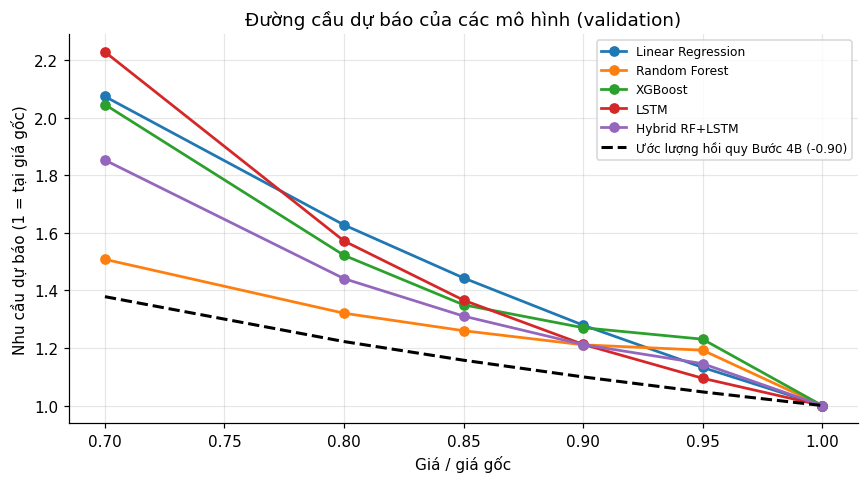

Đã lưu hình: output/ket_qua_duong_cau.png

NHẬN XÉT — Độ co giãn ngầm định: Linear Regression -2.04; Random Forest -1.00; XGBoost -1.84; LSTM -2.25; Hybrid RF+LSTM -1.65. Ước lượng hồi quy độc lập ở Bước 4B: -0.90.


In [30]:
LV = CFG["PRICE_LEVELS"]
curves, sens = {}, []
for k, mdl in M_TR.items():
    q = np.array([(np.clip(np.expm1(mdl.predict(IDX_VA, lv)), 0, None) * CAL[k]).mean() for lv in LV])
    r = q / q[-1]; curves[k] = r
    el = np.polyfit(np.log(LV), np.log(np.maximum(r, 1e-6)), 1)[0]
    sens.append({"Mô hình": NAMES[k], "key": k, "Nhu cầu ở 80% / 100% giá gốc": r[LV.index(0.80)], "Độ co giãn ngầm định": el,
                 "Đúng chiều (không tăng khi giá tăng)": bool(np.all(np.diff(r) <= 1e-3)), "WAPE validation": VA_TAB.loc[NAMES[k], "WAPE"]})
SENS = pd.DataFrame(sens)
display(SENS.drop(columns="key").round(3)); savetab(SENS.drop(columns="key").round(4), "bang_9_do_nhay_gia", index=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
for k, r in curves.items():
    ax.plot(LV, r, "o-", lw=1.8, label=NAMES[k])
ref = np.array(LV) ** ELAS; ax.plot(LV, ref / ref[-1], "k--", lw=2, label=f"Ước lượng hồi quy Bước 4B ({ELAS:.2f})")
ax.set_xlabel("Giá / giá gốc"); ax.set_ylabel("Nhu cầu dự báo (1 = tại giá gốc)"); ax.set_title("Đường cầu dự báo của các mô hình (validation)"); ax.legend(fontsize=8)
savefig("ket_qua_duong_cau", "Đường cầu dự báo của các mô hình")
note("6_3_do_nhay", "Độ co giãn ngầm định: " + "; ".join(f"{r['Mô hình']} {r['Độ co giãn ngầm định']:.2f}" + ("" if r["Đúng chiều (không tăng khi giá tăng)"] else " (sai chiều)") for _, r in SENS.iterrows()) + f". Ước lượng hồi quy độc lập ở Bước 4B: {ELAS:.2f}.")

**Nhận xét kết quả.** Cả 5 mô hình đều phản ứng đúng chiều: giá càng giảm thì cầu dự báo càng tăng. Mức phản ứng khác nhau rõ rệt. Khi giảm giá còn 80% giá gốc, Random Forest dự báo cầu tăng khoảng 32% (độ co giãn ngầm định −1,00), trong khi LSTM dự báo tăng khoảng 57% (−2,25) và Linear Regression khoảng 63% (−2,04). Ước lượng hồi quy hiệu ứng cố định ở Bước 4B là −0,90, tương ứng cầu tăng khoảng 22%. Như vậy các mô hình có WAPE gần nhau nhưng "hiểu" tác động của giá rất khác nhau, đây là điều WAPE không cho thấy.

### 6.4 Chọn mô hình cho engine định giá
Engine ở Notebook 2 so sánh lợi nhuận giữa các mức giá, nên mô hình được chọn cần vừa dự báo chính xác vừa phản ứng với giá đúng chiều và đúng độ lớn. Ba tiêu chí, đều đánh giá trên tập validation (chưa dùng tập test):

1. **Đúng chiều:** cầu dự báo không tăng khi giá tăng.
2. **Độ chính xác:** WAPE validation chênh không quá 1 điểm phần trăm so với mô hình tốt nhất.
3. **Phản ứng giá hợp lý:** độ co giãn ngầm định gần nhất với độ co giãn ước lượng bằng hồi quy ở Bước 4B.

Trong các mô hình đạt tiêu chí 1 và 2, mô hình thỏa tiêu chí 3 tốt nhất được dùng cho engine.

In [31]:
w_min = SENS["WAPE validation"].min()
SENS["WAPE chênh so với tốt nhất"] = SENS["WAPE validation"] - w_min
SENS["Lệch so với hồi quy 4B"] = (SENS["Độ co giãn ngầm định"] - ELAS).abs()
SENS["Đạt tiêu chí 1 và 2"] = SENS["Đúng chiều (không tăng khi giá tăng)"] & (SENS["WAPE chênh so với tốt nhất"] <= 1.0)
cand = SENS[SENS["Đạt tiêu chí 1 và 2"]]
SELECTED = cand.sort_values("Lệch so với hồi quy 4B").key.iloc[0]
SENS["Được chọn"] = SENS.key == SELECTED
tab64 = SENS[["Mô hình", "WAPE validation", "WAPE chênh so với tốt nhất", "Đúng chiều (không tăng khi giá tăng)",
              "Độ co giãn ngầm định", "Lệch so với hồi quy 4B", "Đạt tiêu chí 1 và 2", "Được chọn"]].round(3)
display(tab64); savetab(tab64, "bang_10_chon_mo_hinh", index=False)
r = SENS.set_index("key").loc[SELECTED]
note("6_4_chon", f"Mô hình được chọn cho engine: {NAMES[SELECTED]} (WAPE validation {r['WAPE validation']:.2f}%, "
     f"độ co giãn ngầm định {r['Độ co giãn ngầm định']:.2f} so với {ELAS:.2f} của hồi quy 4B). "
     f"Các mô hình đạt tiêu chí 1 và 2: {', '.join(cand['Mô hình'])}.")

,Mô hình,WAPE validation,WAPE chênh so với tốt nhất,Đúng chiều (không tăng khi giá tăng),Độ co giãn ngầm định,Lệch so với hồi quy 4B,Đạt tiêu chí 1 và 2,Được chọn
0,Linear Regression,38.085,2.594,True,-2.038,1.138,False,False
1,Random Forest,36.223,0.732,True,-1.000,0.100,True,True
2,XGBoost,36.027,0.536,True,-1.838,0.939,True,False
3,LSTM,36.032,0.541,True,-2.248,1.349,True,False
4,Hybrid RF+LSTM,35.491,0.000,True,-1.647,0.748,True,False


Đã lưu bảng: output/tables/bang_10_chon_mo_hinh.csv

NHẬN XÉT — Mô hình được chọn cho engine: Random Forest (WAPE validation 36.22%, độ co giãn ngầm định -1.00 so với -0.90 của hồi quy 4B). Các mô hình đạt tiêu chí 1 và 2: Random Forest, XGBoost, LSTM, Hybrid RF+LSTM.


**Nhận xét kết quả.** Bốn mô hình đạt tiêu chí 1 và 2 (Random Forest, XGBoost, LSTM, Hybrid RF+LSTM); Linear Regression bị loại vì WAPE kém mô hình tốt nhất 2,6 điểm. Trong bốn mô hình còn lại, Random Forest có độ co giãn ngầm định gần ước lượng hồi quy nhất (−1,00 so với −0,90, lệch 0,10), trong khi các mô hình khác lệch 0,75–1,35. Đổi lại, WAPE validation của Random Forest chỉ cao hơn mô hình tốt nhất (Hybrid) 0,73 điểm. **Random Forest được chọn làm mô hình dự báo cho engine định giá.** Nếu dùng mô hình phản ứng giá quá mạnh như LSTM, engine sẽ đánh giá quá cao lợi ích của giảm giá và đề xuất giảm giá nhiều hơn mức hợp lý.

### 6.5 Huấn luyện lại trên train + validation và đánh giá trên test
Mọi lựa chọn (tham số, hệ số hiệu chỉnh, α, mô hình cho engine) đã chốt ở 6.1–6.4. Bước này chỉ huấn luyện lại để dùng dữ liệu gần ngày test nhất, rồi chấm điểm **một lần**. Kèm theo là **khoảng tin cậy 95% bằng bootstrap theo chuỗi** (lấy mẫu lặp 2.000 chuỗi 1.000 lần) cho chênh lệch WAPE so với mô hình được chọn.

Huấn luyện lại xong sau 275s


,WAPE,MAE,RMSE,R2,Bias,Chênh WAPE so với mô hình chọn (KTC 95%)
Linear Regression,37.602,0.392,0.604,0.572,-3.461,+0.90 đến +1.43
Random Forest,36.450,0.380,0.584,0.600,-2.180,— (mốc so sánh)
XGBoost,37.149,0.387,0.593,0.588,-4.251,+0.48 đến +0.90
LSTM,42.285,0.441,0.643,0.516,5.725,+5.50 đến +6.16
Hybrid RF+LSTM,37.873,0.395,0.590,0.591,1.732,+1.25 đến +1.60


Đã lưu bảng: output/tables/bang_11_test.csv


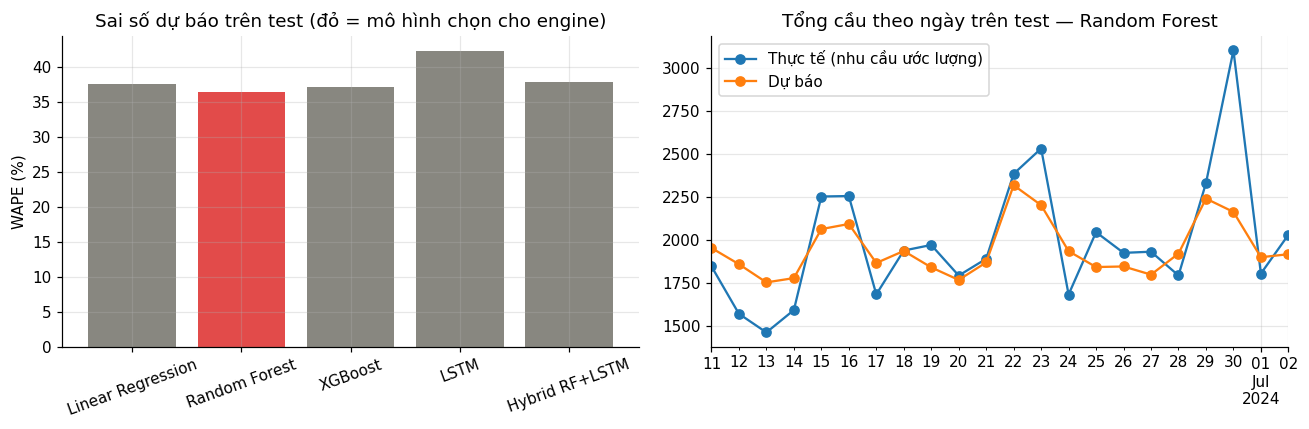

Đã lưu hình: output/ket_qua_test.png

NHẬN XÉT — Trên test, WAPE thấp nhất là Random Forest (36.45%); mô hình chọn cho engine Random Forest đạt 36.45% (R² 0.600, bias -2.18%). Thứ hạng thay đổi so với validation. Khoảng tin cậy chứa 0 nghĩa là chênh lệch với mô hình được chọn không có ý nghĩa thống kê.


In [32]:
t0 = time.time()
M_DEV = {k: make(k, BEST[k]).fit(IDX_DEV) for k in ["LR", "RF", "XGB", "LSTM"]}
M_DEV["Hybrid"] = Hybrid(M_DEV["RF"], M_DEV["LSTM"], best_a)
print(f"Huấn luyện lại xong sau {time.time()-t0:.0f}s")
Q_TE = {k: np.clip(np.expm1(m.predict(IDX_TE)), 0, None) * CAL[k] for k, m in M_DEV.items()}
TE_TAB = pd.DataFrame({NAMES[k]: metrics(q, IDX_TE) for k, q in Q_TE.items()}).T.round(3)
# Bootstrap theo chuỗi
sid = IDX_TE // T_N; useries = np.unique(sid); pos = np.searchsorted(useries, sid)
act = REC_ACT[IDX_TE]; A_s = np.bincount(pos, act)
E_s = {k: np.bincount(pos, np.abs(q - act)) for k, q in Q_TE.items()}
rng = np.random.RandomState(CFG["SEED"]); B = rng.randint(0, len(useries), size=(1000, len(useries)))
w_sel = E_s[SELECTED][B].sum(1) / A_s[B].sum(1)
ci = {}
for k in Q_TE:
    d = (E_s[k][B].sum(1) / A_s[B].sum(1) - w_sel) * 100
    ci[NAMES[k]] = "— (mốc so sánh)" if k == SELECTED else f"{np.percentile(d, 2.5):+.2f} đến {np.percentile(d, 97.5):+.2f}"
TE_TAB["Chênh WAPE so với mô hình chọn (KTC 95%)"] = pd.Series(ci)
display(TE_TAB); savetab(TE_TAB, "bang_11_test")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(TE_TAB.index, TE_TAB.WAPE, color=["#E24B4A" if n == NAMES[SELECTED] else "#888780" for n in TE_TAB.index]); ax[0].set_ylabel("WAPE (%)")
ax[0].set_title("Sai số dự báo trên test (đỏ = mô hình chọn cho engine)"); ax[0].tick_params(axis="x", rotation=20)
dts = P.dt.values[IDX_TE]; daily = pd.DataFrame({"dt": dts, "Thực tế (nhu cầu ước lượng)": act, "Dự báo": Q_TE[SELECTED]}).groupby("dt").sum()
daily.plot(ax=ax[1], marker="o"); ax[1].set_title(f"Tổng cầu theo ngày trên test — {NAMES[SELECTED]}"); ax[1].set_xlabel("")
savefig("ket_qua_test", "Sai số dự báo trên test và tổng cầu theo ngày")
best_te = TE_TAB.WAPE.idxmin()
note("6_5_test", f"Trên test, WAPE thấp nhất là {best_te} ({TE_TAB.WAPE.min():.2f}%); mô hình chọn cho engine {NAMES[SELECTED]} đạt {TE_TAB.loc[NAMES[SELECTED],'WAPE']:.2f}% "
     f"(R² {TE_TAB.loc[NAMES[SELECTED],'R2']:.3f}, bias {TE_TAB.loc[NAMES[SELECTED],'Bias']:+.2f}%). Thứ hạng " + ("giữ nguyên" if VA_TAB.WAPE.idxmin() == best_te else "thay đổi")
     + " so với validation. Khoảng tin cậy chứa 0 nghĩa là chênh lệch với mô hình được chọn không có ý nghĩa thống kê.")

**Nhận xét kết quả.** *(sẽ cập nhật sau khi chạy)*

## Lưu kết quả cho Notebook 2
Lưu bảng dữ liệu đã xử lý, ma trận đặc trưng, mô hình được chọn (huấn luyện trên train + validation) cùng XGBoost để tham khảo, và file cấu hình.

In [33]:
DATA_DIR, MOD_DIR = os.path.join(OUT, "data"), os.path.join(OUT, "models")
keep = ["key", "store_id", "product_id", "first_category_id", "dt", "t", "disc", "is_disc", "activity_flag", "holiday_flag", "precpt",
        "avg_temperature", "avg_humidity", "avg_wind_level", "obs", "rec", "rec_src", "stockout", "so_hrs", "excl"]
P[keep].to_parquet(os.path.join(DATA_DIR, "panel.parquet"), index=False)
np.save(os.path.join(DATA_DIR, "X_rec.npy"), XR); np.save(os.path.join(DATA_DIR, "ldl1.npy"), LDL1); np.save(os.path.join(DATA_DIR, "seq.npy"), SEQ)
def save_model(k, m):
    if k == "LSTM":
        torch.save({"state": m.net.state_dict(), "p": m.p, "sm": m.sm, "ss": m.ss, "tm": m.tm, "ts": m.ts, "ym": m.ym, "ys": m.ys}, os.path.join(MOD_DIR, "LSTM.pt"))
    elif k == "Hybrid":
        save_model("RF", m.rf); save_model("LSTM", m.lstm)
    else:
        joblib.dump(m.m, os.path.join(MOD_DIR, f"{k}.joblib"))
for k in {SELECTED, "XGB"}: save_model(k, M_DEV[k])
META = dict(CFG=CFG, FEATS=FEATS, SEQ_COLS=SEQ_COLS, SELECTED=SELECTED, ROBUST="XGB" if SELECTED != "XGB" else "LR", BEST=BEST, ALPHA=best_a,
            CAL=CAL, ELAS_EDA=ELAS, D0=str(D0.date()), S_N=S_N, T_N=T_N, T_WARM=T_WARM, T_TRAIN_END=T_TRAIN_END, T_VAL_END=T_VAL_END, T_END=T_END,
            LOST_SHARE=float(LOST_ALL), SHARE_PROFITABLE_DISC=float(SHARE_OK), NOTES=NOTES)
if META["ROBUST"] == "LR": save_model("LR", M_DEV["LR"])
json.dump(META, open(os.path.join(OUT, "meta_notebook1.json"), "w", encoding="utf-8"), ensure_ascii=False, indent=2, default=str)
print("Đã lưu vào", OUT); print(sorted(os.listdir(MOD_DIR)), sorted(os.listdir(DATA_DIR)))

Đã lưu vào /content/drive/MyDrive/MASTER UEH/output
['LSTM.pt', 'RF.joblib', 'XGB.joblib'] ['X_rec.npy', 'ldl1.npy', 'panel.parquet', 'seq.npy']


## Tóm tắt kết quả Notebook 1

In [34]:
print("=" * 90); print("TÓM TẮT NOTEBOOK 1 — thời gian chạy:", f"{(time.time()-T0_ALL)/60:.1f} phút")
for k, v in NOTES.items(): print(f"\n[{k}] {v}")
print("\n" + "-" * 90); print("Kết quả test:"); print(TE_TAB.to_string())
print("\nĐộ nhạy giá (validation):"); print(SENS.drop(columns="key").round(3).to_string(index=False))
print("\nHình đã lưu:"); [print(" -", n, "—", t) for n, t in FIG_LOG]
print("=" * 90)

TÓM TẮT NOTEBOOK 1 — thời gian chạy: 32.6 phút

[1_du_lieu] Bộ dữ liệu có 4,850,000 quan sát thật trong 97 ngày năm 2024, đạt yêu cầu ≥200 mẫu và trong vòng 7 năm. Lượng bán đã được chuẩn hóa (trung vị 0.70), nên mọi kết quả kinh doanh được báo theo tỷ lệ % chứ không theo tiền. Thành phố 0 có 290 cửa hàng, lớn nhất trong 18 thành phố.

[2_pham_vi] Sau khi lọc còn 8,179 chuỗi đủ điều kiện; lấy mẫu phân tầng 2,003 chuỗi × 97 ngày = 194,291 quan sát (tỷ trọng danh mục trong mẫu sát với toàn thành phố). Quan sát bất thường bị loại khỏi huấn luyện chiếm 0.14% mẫu. 0 quan sát bán trên giá gốc (0.00%) — quá ít để học vùng tăng giá, nên engine giữ trần = giá gốc.

[3_khoi_phuc] Ngày có hết hàng chiếm 36.3% mẫu; 4.5% số quan sát hết hàng quá sớm nên bị loại. Kiểm chứng trên 30,000 ngày còn hàng giả lập hết hàng: giữ nguyên lượng bán bị chặn lệch -36.2%, hiệu chỉnh theo tỷ trọng giờ chỉ lệch +0.1% (WAPE 27.6% so với 36.2%). Ước tính 15.4% doanh số bị mất do hết hàng. 0 chuỗi dùng tỷ trọng giờ củ

In [ ]:
# Lưu chính notebook này (kèm toàn bộ kết quả) vào thư mục đồ án trên Drive
if IN_COLAB:
    from google.colab import _message
    nb = _message.blocking_request("get_ipynb", timeout_sec=120)["ipynb"]
    path = os.path.join(BASE_DIR, CFG["NOTEBOOK_NAME"])
    json.dump(nb, open(path, "w", encoding="utf-8"), ensure_ascii=False, indent=1)
    print("Đã lưu notebook:", path)